# 11 · Drug route

For anyone checking how Open Altio reads the route families a drug record could be in, and what the label flags must do where an ingredient's labels differ by form. The rule is `rules/drug-route.md`; the reviewed tables are in `mappings/faers/route/`.

A **drug record** is one drug of one report: (`era_T`, `primaryid`, `quarter_T`, `drug_seq`). Since 2024Q4 FDA can write one record on several rows, one per dosage regimen, so everything below counts records (distinct keys) or cases, never FDA's rows. **Suspect** means PS or SS. **Cases** are the default case set: the latest version of each case, less FDA's deleted cases and the probable duplicates set aside.

**What it reads.** A release folder built by the command line (`open-altio demo` builds one from FDA's latest quarter, `open-altio build` from every quarter), named by `OPEN_ALTIO_RELEASE` or by `RELEASE` in the first code cell. Where the release carries no `drug_route_T` (built before the route step), the notebook builds it with the release code; where it carries no `drug_substance_T`, it reads each record's ingredient from the DiAna dictionary file named by `OPEN_ALTIO_DIANA_DICTIONARY` (DiAna, CC BY 4.0). Section 3 also reads the label step's chosen labels and their safety sections from the folder `OPEN_ALTIO_LABELS` (`label_candidates_T.parquet`, `label_sections_T.parquet`). Everything is read only; working tables go to a scratch database beside the executed notebook.

Sections: 1 how filled route and dose form are; 2 how the family table was made; 3 the families each record ends with; 4 FAERS evidence for every value that allows several families; 5 which ingredients' labels differ by form, and how many records they hold; 6 which labels each record matches; then the decisions, each provisional until confirmed, and two notes on FDA's route words.

In [1]:
import dataclasses
import hashlib
import json
import os
import re
import textwrap
from collections import Counter, defaultdict
from functools import reduce
from pathlib import Path

import duckdb
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from open_altio.faers import route
from open_altio.faers.insights.cards.notebook import out_dir
from open_altio.faers.insights.source import connect, release_folder

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)
SERIES = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#7a7a72",
    "#c3c2b7",
]  # fixed categorical order
mpl.rcParams.update(
    {
        "axes.prop_cycle": mpl.cycler(color=SERIES),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "figure.dpi": 100,
        "axes.titlesize": 12,
    }
)
BACKS = "Backs: rules/drug-route.md"


def title(ax, claim, guide, question, width=95):
    """Title a chart with its point; the subtitle says how to read it, what it asks,
    and the rule it backs."""
    sub = textwrap.fill(f"{guide} {question}", width) + "\n" + BACKS
    ax.set_title(
        claim,
        loc="left",
        fontsize=12,
        fontweight="bold",
        pad=12 + 11 * (sub.count("\n") + 1),
    )
    ax.annotate(
        sub,
        (0, 1),
        xycoords="axes fraction",
        xytext=(0, 5),
        textcoords="offset points",
        fontsize=9,
        color="0.35",
        va="bottom",
    )


def pct(a, b):
    return f"{100 * a / b:.1f}%" if b else "n/a"


T = route.RouteTables.read()
FAMILIES = route.families()
UNKNOWN = FAMILIES[-1]

# The release folder this notebook reads; None reads $OPEN_ALTIO_RELEASE.
# No release yet? Build one with `open-altio demo` or `open-altio build`.
RELEASE = None
SOURCE = release_folder(RELEASE)
LABELS = Path(os.environ["OPEN_ALTIO_LABELS"]).expanduser()
con = connect(SOURCE)
BUILD_ID = hashlib.md5((SOURCE / "manifest.json").read_bytes()).hexdigest()[:8]
WORK = out_dir() / "11_drug_route" / f"{SOURCE.name}-{BUILD_ID}.duckdb"
WORK.parent.mkdir(parents=True, exist_ok=True)
con.execute(
    "SET memory_limit = '6GB'; SET threads = 4; SET max_temp_directory_size = '20GB'; SET "
    "preserve_insertion_order = false; "
    f"SET temp_directory = '{WORK.parent / 'tmp'}'"
)
con.execute(f"ATTACH '{WORK}' AS w")


def q(sql):
    return con.execute(sql).fetchdf()


def one(sql):
    return con.execute(sql).fetchone()


RELEASE_TABLES = json.loads((SOURCE / "manifest.json").read_text(encoding="utf-8"))["tables"]


def in_release(t):
    return t in RELEASE_TABLES


def in_work(t):
    return (
        one(
            f"SELECT count(*) FROM duckdb_tables() WHERE database_name = 'w' AND table_name = '{t}'"
        )[0]
        > 0
    )


KEY = ", ".join(route.KEY)
print("release:", SOURCE.name, "| working tables:", WORK.name)

release: 2026Q2-oap-final3-local | working tables: 2026Q2-oap-final3-local-140a5c16.duckdb


The notebook builds its working tables once (a few minutes; later runs reuse them):

- `drug_route_T`: the release's own, or built here by the release code (`open_altio.faers.route.build`) into the scratch database.
- `w.rec_T`: one row per suspect drug record in the default case set, with FDA's route and dose form as written (the record's first, where its rows differ), its cleaned route, its case and its ingredient (`drug_substance_T`, else DiAna's by the drug name, else FDA's `prod_ai`).
- For section 4: `w.rid_T` numbers those records; `w.read_T` holds every row FDA wrote for each, as the rule reads it (the route and dose form that say something and the form words of the name, each with its families as a bit mask); `w.unit_T` each row as the rule reads it; `w.pair_T` each value's independent clue.

In [2]:
if not in_release("drug_route_T"):
    if not in_work("drug_route_T"):
        drugs = (SOURCE / "parquet" / "drug_latest_T.parquet").as_posix()
        con.execute(
            f"CREATE OR REPLACE VIEW w.drug_latest_T AS SELECT * FROM read_parquet('{drugs}')"
        )
        con.execute("USE w")
        route.build(con)
        con.execute("DROP VIEW drug_latest_T")
        con.execute("USE memory")
    con.execute("CREATE OR REPLACE TEMP VIEW drug_route_T AS SELECT * FROM w.drug_route_T")

PUNCT = set("!\"#$%&'()*+,-./:;<=>?@[\\]^_`{|}~")


def diana_key(name):
    """DiAna's 2023 key: lower case, one trailing period, spaces collapsed,
    leading and trailing punctuation twice, brackets kept."""
    s = name.lower().strip()
    s = s.removesuffix(".")
    s = re.sub(r"\s+", " ", s.strip())
    for _ in range(2):
        s = s.rstrip("".join(PUNCT - {")"})).strip()
        s = s.lstrip("".join(PUNCT - {"("})).strip()
    return s.replace("( ", "(").replace(" )", ")")


if not in_work("rec_T"):
    if in_release("drug_substance_T"):
        ingredient = (
            f"LEFT JOIN (SELECT {KEY}, substance_T AS sub_T FROM drug_substance_T) s USING ({KEY})"
        )
    else:
        d = pd.read_csv(
            Path(os.environ["OPEN_ALTIO_DIANA_DICTIONARY"]).expanduser(),
            sep=";",
            dtype=str,
            encoding="utf-8-sig",
            keep_default_na=False,
        )
        d = d[~d.Substance.isin(["", "na", "NA"])]
        diana = dict(zip(d.drugname, d.Substance, strict=False))
        names = q("SELECT DISTINCT drugname FROM drug_latest_T WHERE drugname IS NOT NULL")
        names["sub_T"] = [diana.get(diana_key(n)) for n in names.drugname]
        names = names.dropna()
        names["sub_T"] = [";".join(sorted(p.strip() for p in s.split(";"))) for s in names.sub_T]
        con.register("names_df", names)
        con.execute("CREATE OR REPLACE TABLE w.name_sub_T AS SELECT * FROM names_df")
        ingredient = "LEFT JOIN w.name_sub_T s USING (drugname)"
    con.execute(f"""
    CREATE TABLE w.rec_T AS
    WITH k AS (SELECT {KEY}, min(drugname) AS drugname, min(prod_ai_norm_T) AS prod_ai,
      min(route) AS route, min(dose_form) AS dose_form,
                      count(*) AS rows_T, coalesce(min(route) <> max(route),
                        false) OR (count(route) BETWEEN 1 AND count(*) - 1) AS routes_differ_T,
                      coalesce(min(dose_form) <> max(dose_form),
                        false) OR (count(dose_form) BETWEEN 1 AND count(*) - 1) AS forms_differ_T
               FROM drug_latest_T WHERE role_cod IN ('PS', 'SS') GROUP BY ALL)
    SELECT k.*, c.case_key_T, left(k.quarter_T, 4)::INT AS year_T, s.sub_T,
           array_to_string(list_sort(string_split(lower(k.prod_ai), '\\')), ';') AS prod_ai_sub_T,
           r.route_T, r.route_source_T, r.route_family_T, r.route_families_T
    FROM k JOIN case_latest_T c USING (era_T, primaryid, quarter_T)
    {ingredient}
    JOIN drug_route_T r USING ({KEY})
    WHERE c.dup_kept_T""")
REC = one("SELECT count(*), count(DISTINCT case_key_T) FROM w.rec_T")
print(f"Suspect drug records in the default case set: {REC[0]:,}, in {REC[1]:,} cases.")

Suspect drug records in the default case set: 41,002,690, in 20,296,307 cases.


## 1. How filled are route and dose form?

FDA's `route` is a word from ICH's E2B route list (code list 14: `Oral`, `Intravenous (not otherwise specified)`, `Unknown`), now and then another spelling. `mappings/faers/route/families.csv` gives each such word the set of families a drug given that way could be in: `Subcutaneous` only `injected`, `Oral` both `by_mouth` and `under_tongue` (it is written for sublingual tablets too), `Unknown` none. `dose_form` is free text with thousands of spellings, and legacy AERS has no dose form column.

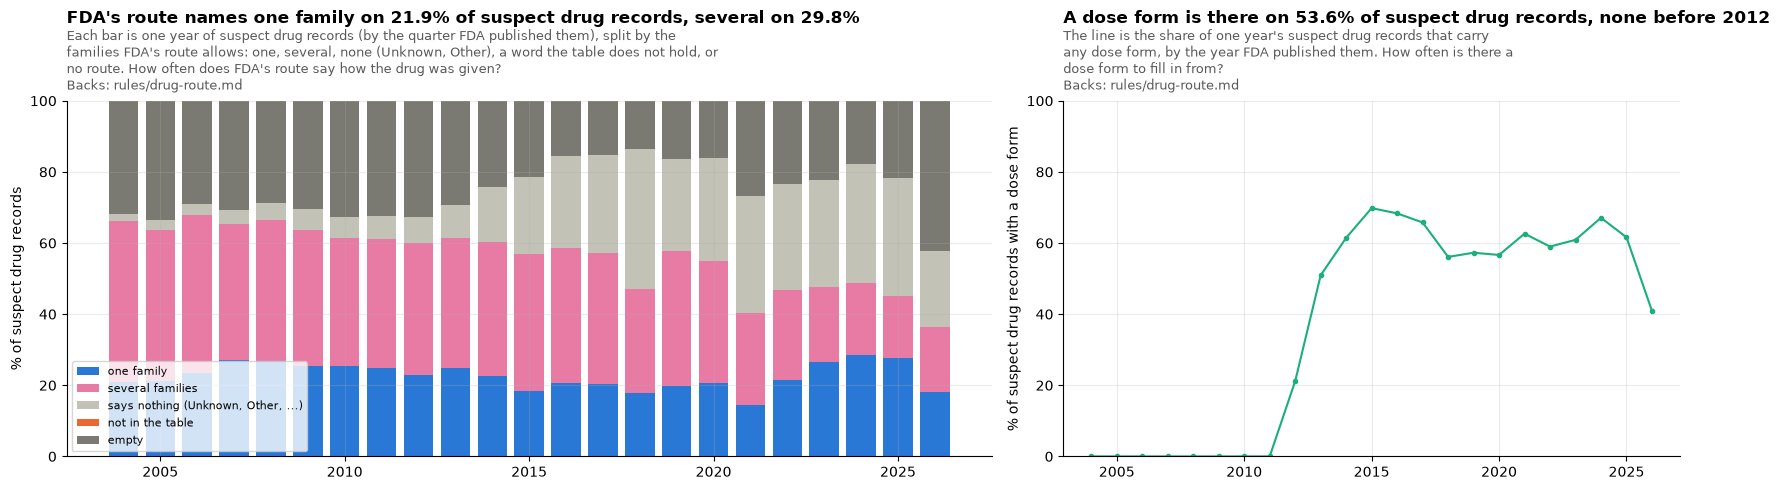

FDA's route on suspect drug records: one family 8,970,946 (21.9%); several families 12,221,890 (29.8%); says nothing (Unknown, Other, ...) 10,635,397 (25.9%); not in the table 97 (0.0%); empty 9,174,360 (22.4%).
Route words the table does not hold: 71, on 97 records; the commonest: Intraglandular (5), Nasal J-tube (5), arm (3), Gastric port (3), administered to the vascular scalp (3)


In [3]:
routes = q("SELECT route, count(*) AS n FROM w.rec_T GROUP BY 1")


def route_says(r):
    if not isinstance(r, str):
        return "empty"
    found = T.families("route", r)
    if found is None:
        return "not in the table"
    if not found:
        return "says nothing (Unknown, Other, ...)"
    return "one family" if len(found) == 1 else "several families"


routes["says"] = [route_says(r) for r in routes.route]
con.register("route_says_df", routes[["route", "says"]])
SAYS = [
    "one family",
    "several families",
    "says nothing (Unknown, Other, ...)",
    "not in the table",
    "empty",
]
by_year = q("""SELECT year_T, s.says, count(*) AS n, count(*)
  FILTER (WHERE dose_form IS NOT NULL) AS with_form
               FROM w.rec_T r LEFT JOIN route_says_df s ON s.route IS NOT DISTINCT FROM r.route
                 GROUP BY ALL""")
share = (
    by_year.pivot_table(index="year_T", columns="says", values="n", aggfunc="sum")
    .reindex(columns=SAYS)
    .fillna(0)
)
share = 100 * share.div(share.sum(axis=1), axis=0)
yr = by_year.groupby("year_T")[["with_form", "n"]].sum()
form_share = 100 * yr.with_form / yr.n
tot = by_year.groupby("says").n.sum().reindex(SAYS).fillna(0)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1.5, 1]})
bottom = np.zeros(len(share))
for s, color in zip(SAYS, [SERIES[0], SERIES[4], SERIES[7], SERIES[1], SERIES[6]], strict=True):
    a1.bar(share.index, share[s], bottom=bottom, color=color, label=s, width=0.8)
    bottom += share[s].values
a1.set_ylim(0, 100)
a1.set_ylabel("% of suspect drug records")
a1.legend(fontsize=8, loc="lower left")
title(
    a1,
    f"FDA's route names one family on {pct(tot['one family'], tot.sum())} of suspect drug "
    f"records, several on {pct(tot['several families'], tot.sum())}",
    "Each bar is one year of suspect drug records (by the quarter FDA published them), split by "
    "the families FDA's route allows: one, several, none (Unknown, Other), a word the table "
    "does not hold, or no route.",
    "How often does FDA's route say how the drug was given?",
    width=100,
)
a2.plot(form_share.index, form_share.values, marker="o", ms=3, color=SERIES[2])
a2.set_ylim(0, 100)
a2.set_ylabel("% of suspect drug records with a dose form")
title(
    a2,
    f"A dose form is there on {pct(yr.with_form.sum(), yr.n.sum())} of suspect drug records, none "
    "before 2012",
    "The line is the share of one year's suspect drug records that carry any dose form, by the "
    "year FDA published them.",
    "How often is there a dose form to fill in from?",
    width=70,
)
plt.tight_layout()
plt.show()
print(
    "FDA's route on suspect drug records: "
    + "; ".join(f"{s} {int(tot[s]):,} ({pct(tot[s], tot.sum())})" for s in SAYS)
    + "."
)
unread = routes[routes.says == "not in the table"].sort_values("n", ascending=False)
print(
    f"Route words the table does not hold: {len(unread)}, on {unread.n.sum():,} records; "
    "the commonest: "
    + ", ".join(f"{r} ({n:,})" for r, n in unread.head(5)[["route", "n"]].itertuples(index=False))
)

**Section 1, chart by chart**

- *Route by year.* **Shows** each year's suspect drug records by the families FDA's route allows. **Point** FDA's route names one family on 21.9% of suspect drug records and several on 29.8% (mostly `Oral`); 25.9% say nothing (Unknown, Other, Transplacental), a share that grew from a few percent before 2013 to a third or more since 2016; 22.4% are empty. Only 97 records hold a word the table does not have. **So what** FDA's route alone settles one record in five; the dose form and the name are needed to settle more.
- *Dose form by year.* **Shows** the share of each year's suspect drug records with any dose form. **Point** 53.6% overall, none before 2012 (legacy AERS has no dose form column), 55% to 70% in most years since 2014. **So what** The dose form can narrow only FAERS records; for legacy records the route and the name are all there is.

## 2. How the family table was made

`mappings/faers/route/families.csv` gives every value FDA writes about how a drug was given the set of route families a drug given that way could be in. It rests on two principles:

- **Every value maps to the set of families it could be.** A value that names one form gets one family; a value that real products of several forms share gets all of them; a value that says nothing gets none.
- **A family is added only when FAERS has real cases of it.** A family a value could mean in theory, with no reports behind it, is not added.

How it was made: one written instruction (`mappings/faers/route/review/instructions.md`, quoted below) was followed by two independent runs, each without seeing the other (`review/run_a.csv`, `review/run_b.csv`). Where they gave the same families, the value keeps them; where they differed, it takes the union of both. A reviewer then proposed ten corrections (`review/corrections.csv`); a correction is applied only where accepted. Last, FAERS's own records (section 4) removed five families that FAERS shows only as mistakes (`review/evidence-removals.csv`; decision 2).

> # Route families: how each value is placed
> 
> Each value is one way FDA's data says how a drug was given: a word from the route field of an adverse event report, a dose form from a report, a word found in a reported drug name, or a route name on an FDA drug label. Place each value in every family that a drug given that way could belong to. The families exist to match a report with the FDA label for the same form of the drug, so the question for each value is: which kinds of product could a report or label with this value be about?
> 
> The families follow WHO's administration routes (oral, parenteral, rectal, nasal, vaginal, inhalation, sublingual or buccal, transdermal), plus forms WHO gives no doses for:
> 
> - **by_mouth**: swallowed, into the stomach (including through a stomach tube).
> - **under_tongue**: absorbed through the lining of the mouth (sublingual, buccal, oromucosal).
> - **injected**: by injection, infusion or implant into the body.
> - **inhaled**: breathed into the lungs.
> - **nasal**: into the nose.
> - **rectal**: into the rectum.
> - **vaginal**: into the vagina.
> - **transdermal**: a patch or system through the skin, for an effect in the body.
> - **skin**: on the skin, for a local effect.
> - **eye**: on or into the eye.
> - **ear**: into the ear.
> - **other**: a real way of giving a drug that fits none of the above (for example into the bladder, or a dialysis fluid).
> 
> Rules:
> 
> 1. List every family that is plausible for a real product given that way, even a rare one. Leave a family out only when it is not plausible.
> 2. List exactly one family only when no other is plausible.
> 3. List no family when the value says nothing about how the drug was given ("unknown", "other", "not specified").
> 4. Judge the value as written. Do not drop a family because it is less common than another.
> 5. Give a one-line reason whenever you list more than one family, or the value is unusual.
> 

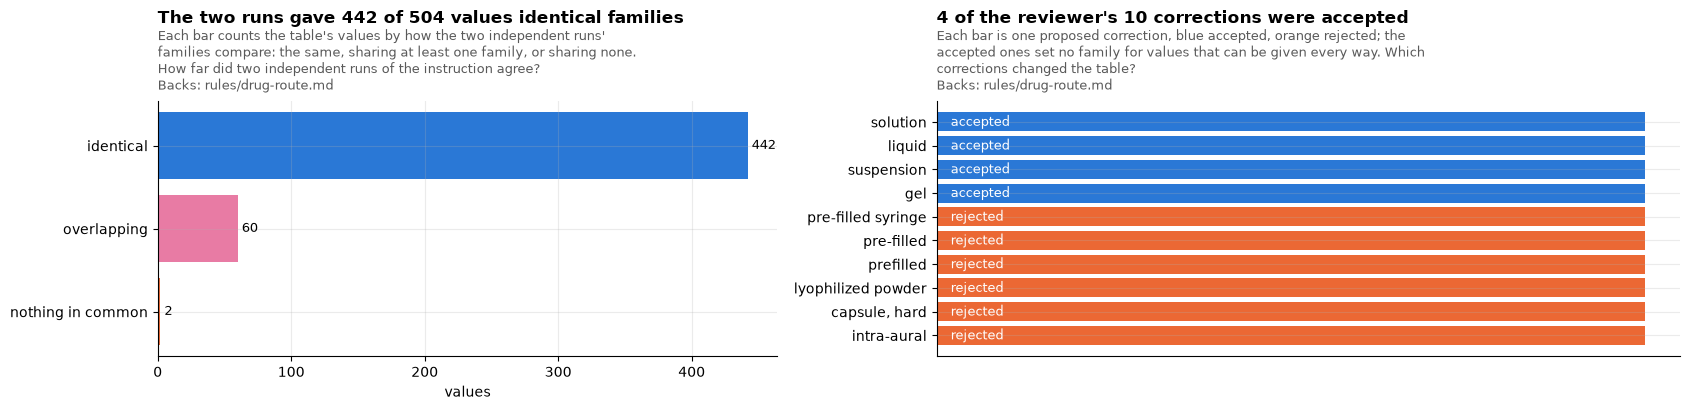

Values where the runs share nothing: liquid (FDA dose form field), solution (FDA dose form field)
accepted: FDA dose form field, solution: -by_mouth;ear;eye;inhaled;injected;nasal;other;rectal;skin;transdermal;under_tongue;vaginal
accepted: FDA dose form field, liquid: -by_mouth;ear;eye;inhaled;injected;nasal;other;rectal;skin;transdermal;under_tongue;vaginal
accepted: FDA dose form field, suspension: -by_mouth;ear;eye;inhaled;injected;nasal;other;rectal;skin;under_tongue
accepted: FDA dose form field, gel: -by_mouth;eye;nasal;other;rectal;skin;transdermal;under_tongue;vaginal
rejected: FDA dose form field, pre-filled syringe: +by_mouth
rejected: word in the drug name, pre-filled: +by_mouth
rejected: word in the drug name, prefilled: +by_mouth
rejected: FDA dose form field, lyophilized powder: +eye
rejected: FDA dose form field, capsule, hard: +vaginal
rejected: FDA route field, intra-aural: +injected


In [4]:
from IPython.display import Markdown, display

tables = Path(route.__file__).resolve().parents[4] / "mappings" / "faers" / "route"
review = tables / "review"
display(
    Markdown("> " + (review / "instructions.md").read_text(encoding="utf-8").replace("\n", "\n> "))
)
run_a = pd.read_csv(review / "run_a.csv", dtype=str, keep_default_na=False)
run_b = pd.read_csv(review / "run_b.csv", dtype=str, keep_default_na=False)
runs = run_a.merge(run_b, on=["source", "value"], suffixes=("_a", "_b"))


def agreement(a, b):
    a, b = set(x for x in a.split(";") if x), set(x for x in b.split(";") if x)
    return "identical" if a == b else "overlapping" if a & b else "nothing in common"


runs["agreement"] = [agreement(a, b) for a, b in zip(runs.families_a, runs.families_b, strict=True)]
AGREE = ["identical", "overlapping", "nothing in common"]
agree = runs.agreement.value_counts().reindex(AGREE).fillna(0).astype(int)
corrections = pd.read_csv(review / "corrections.csv", dtype=str, keep_default_na=False)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
a1.barh(AGREE[::-1], agree[AGREE[::-1]], color=[SERIES[1], SERIES[4], SERIES[0]])
for i, k in enumerate(AGREE[::-1]):
    a1.text(agree[k] + 3, i, f"{agree[k]}", va="center", fontsize=9)
a1.set_xlabel("values")
title(
    a1,
    f"The two runs gave {agree['identical']} of {len(runs)} values identical families",
    "Each bar counts the table's values by how the two independent runs' families compare: the "
    "same, sharing at least one family, or sharing none.",
    "How far did two independent runs of the instruction agree?",
    width=75,
)
acc = corrections.accepted.map({"yes": "accepted", "no": "rejected"})
a2.barh(
    corrections.value[::-1],
    [1] * len(corrections),
    color=[SERIES[0] if x == "accepted" else SERIES[1] for x in acc[::-1]],
)
a2.set_xticks([])
for i, x in enumerate(acc[::-1]):
    a2.text(0.02, i, x, va="center", fontsize=9, color="white")
title(
    a2,
    f"{(acc == 'accepted').sum()} of the reviewer's {len(corrections)} corrections were accepted",
    "Each bar is one proposed correction, blue accepted, orange rejected; the accepted ones set "
    "no family for values that can be given every way.",
    "Which corrections changed the table?",
    width=80,
)
plt.tight_layout()
plt.show()
print(
    "Values where the runs share nothing: "
    + ", ".join(
        f"{r.value} ({r.source})" for r in runs[runs.agreement == "nothing in common"].itertuples()
    )
)
for r in corrections.itertuples():
    change = f"+{r.added}" if r.added else f"-{r.removed}" if r.removed else ""
    print(f"{'accepted' if r.accepted == 'yes' else 'rejected'}: {r.source}, {r.value}: {change}")

### What the table holds

`mappings/faers/route/families.csv` gives every value its set of families. Two independent runs placed every value by one written instruction; where they differed, the value takes the union of both; a reviewer's accepted corrections come last. The chart shows how many families the values allow, by where they are written, and how each row was decided.

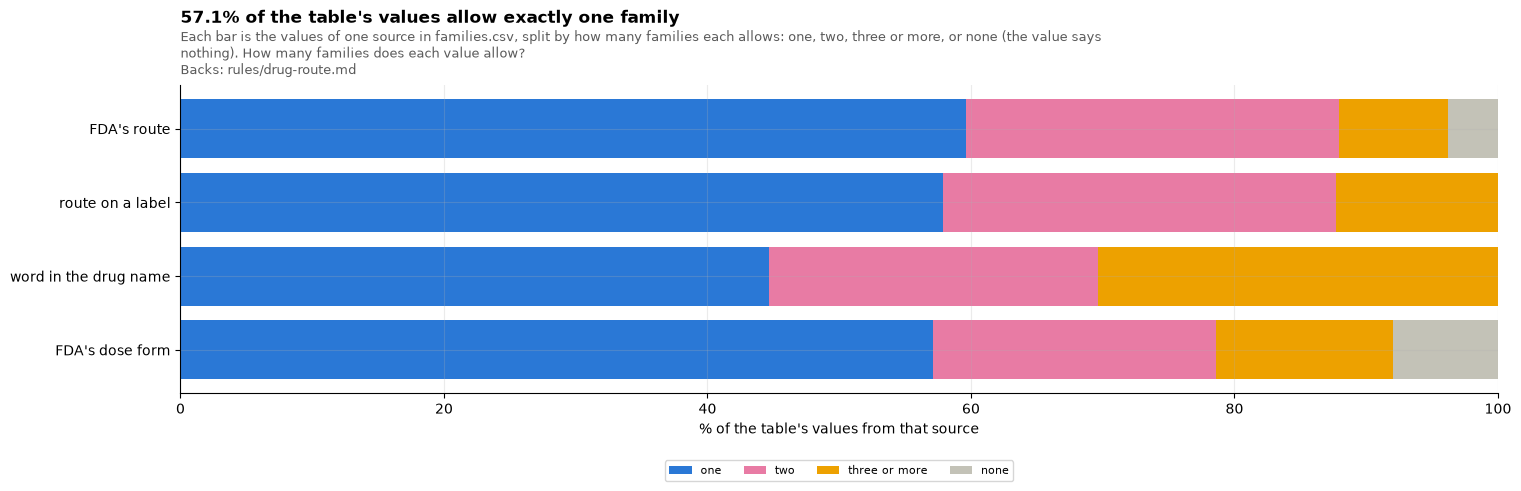

families.csv: 504 values; decided by both runs 440; union of two runs 56; reviewer correction, accepted 4; FAERS evidence 4


In [5]:
tables = Path(route.__file__).resolve().parents[4] / "mappings" / "faers" / "route"
fam_table = pd.read_csv(tables / "families.csv", dtype=str, keep_default_na=False)
fam_table["count"] = [len([f for f in x.split(";") if f]) for x in fam_table.families]
fam_table["allows"] = pd.cut(
    fam_table["count"], [-1, 0, 1, 2, 99], labels=["none", "one", "two", "three or more"]
)
ALLOWS = ["one", "two", "three or more", "none"]
SOURCE_WORDS = {
    "route": "FDA's route",
    "dose_form": "FDA's dose form",
    "drugname": "word in the drug name",
    "label": "route on a label",
}
counts = (
    fam_table.groupby(["source", "allows"], observed=False)
    .size()
    .unstack()
    .reindex(columns=ALLOWS)
    .fillna(0)
)
decided = fam_table.decided_by.value_counts()
fig, ax = plt.subplots(figsize=(17, 4))
left = np.zeros(len(counts))
for a, color in zip(ALLOWS, [SERIES[0], SERIES[4], SERIES[3], SERIES[7]], strict=True):
    vals = 100 * counts[a] / counts.sum(axis=1)
    ax.barh([SOURCE_WORDS[s] for s in counts.index], vals, left=left, color=color, label=a)
    left += vals.values
ax.set_xlim(0, 100)
ax.set_xlabel("% of the table's values from that source")
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2))
title(
    ax,
    f"{pct((fam_table['count'] == 1).sum(), len(fam_table))} of the table's values allow exactly "
    "one family",
    "Each bar is the values of one source in families.csv, split by how many families each allows: "
    "one, two, three or more, or none (the value says nothing).",
    "How many families does each value allow?",
    width=150,
)
plt.show()
print(
    f"families.csv: {len(fam_table)} values; decided by "
    + "; ".join(f"{k} {v}" for k, v in decided.items())
)

**Section 2, chart by chart**

- *Run agreement.* **Shows** the table's 504 values by how the two independent runs' families compare. **Point** 442 values got identical families, 60 overlapping ones (the value takes the union), and 2 nothing in common: `solution` and `liquid`, where one run listed every family and the other none. The table marks 440 rows "both runs": two of the 442, `suspension` and `gel`, were then corrected. **So what** Most values are plain to two readers working alone; the union keeps every family either thought plausible.
- *Corrections.* **Shows** the reviewer's ten proposed corrections and which were accepted. **Point** Four were accepted: `solution`, `liquid`, `suspension` and `gel` set to no family, because they can be given every way. Six were rejected because FAERS has no real cases behind them: by mouth for `pre-filled syringe`, `pre-filled` and `prefilled`, the eye for `lyophilized powder`, the vagina for `capsule, hard`, injection for `intra-aural`; those six keep the runs' union. **So what** A family enters the table only with FAERS cases behind it.
- *Families per value.* **Shows** the values of `families.csv` by how many families each allows. **Point** More than half allow exactly one family; route words and label routes are the most often certain, words in drug names the least. **So what** Every set a record ends with traces back to rows anyone can read, with a reason wherever a value allows several.

## 3. The families each record ends with

`drug_route_T` reads each row FDA wrote for a record alone: the row keeps the families that every source on it that says something allows (FDA's route, its dose form and each form word of its drug name), or, when they allow none in common, every family any of them names. A row is one dosage regimen, so the record keeps every family one of its rows could be in (rule `drug-route`). The left chart says how many families records end with; the right one which sets are commonest.

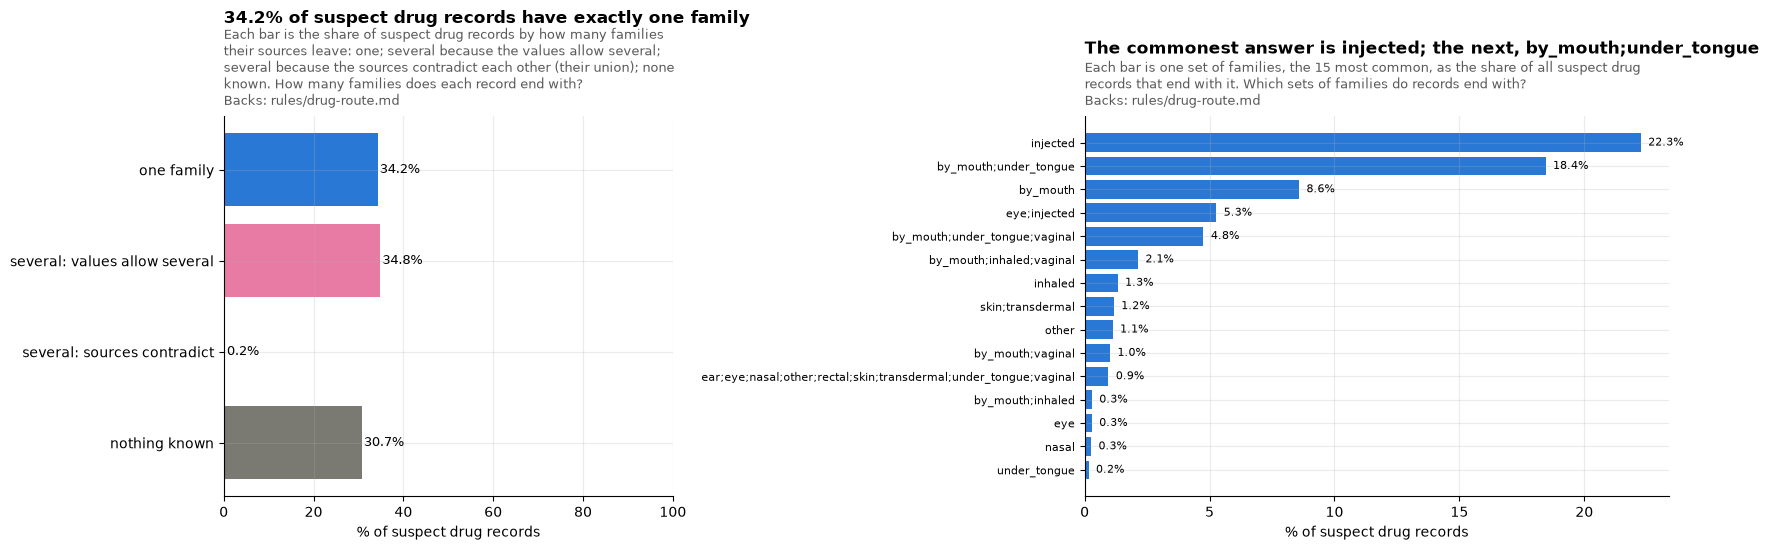

Suspect drug records: one family 14,041,599 (34.2%); several: values allow several 14,279,949 (34.8%); several: sources contradict 89,418 (0.2%); nothing known 12,591,724 (30.7%).
Which fields said something: none 12,591,724; route+dose_form 12,190,575; route 8,502,393; dose_form 6,845,903; route+dose_form+drugname 247,236; drugname 209,663; route+drugname 163,751; dose_form+drugname 162,027; disagree 89,418
Cases: 20,296,307; every suspect record with one family in 6,803,227 (33.5%), at least one in 8,524,246 (42.0%).
Records FDA wrote on several rows: 278,420; their rows differ in route or dose form for 93,854, and for 1,582 of those a row's sources contradict each other.


In [6]:
SHAPE = [
    "one family",
    "several: values allow several",
    "several: sources contradict",
    "nothing known",
]
shape = (
    q(f"""
    SELECT CASE WHEN route_families_T IS NULL THEN 'nothing known'
                WHEN route_family_T <> '{UNKNOWN}' THEN 'one family'
                WHEN route_source_T = 'disagree' THEN 'several: sources contradict'
                ELSE 'several: values allow several' END AS shape,
           count(*) AS n, count(DISTINCT case_key_T) AS cases
    FROM w.rec_T GROUP BY 1""")
    .set_index("shape")
    .reindex(SHAPE)
    .fillna(0)
)
sets = q("""SELECT route_families_T AS families, count(*) AS n FROM w.rec_T
            WHERE route_families_T IS NOT NULL GROUP BY 1 ORDER BY 2 DESC LIMIT 15""")
by_source = q(
    "SELECT route_source_T AS source, count(*) AS n FROM w.rec_T GROUP BY 1 ORDER BY 2 DESC"
)
cases_known = one(f"""SELECT count(*), count(*) FILTER (WHERE all_known), count(*)
    FILTER (WHERE any_known) FROM (
    SELECT case_key_T, bool_and(route_family_T <> '{UNKNOWN}') AS all_known,
      bool_or(route_family_T <> '{UNKNOWN}') AS any_known
    FROM w.rec_T GROUP BY 1)""")
rows_split = one("""
    SELECT count(*) FILTER (WHERE rows_T > 1),
           count(*) FILTER (WHERE rows_T > 1 AND (routes_differ_T OR forms_differ_T)),
           count(*) FILTER (WHERE rows_T > 1 AND (routes_differ_T OR forms_differ_T)
                                             AND route_source_T = 'disagree')
    FROM w.rec_T""")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 5.6), gridspec_kw={"width_ratios": [1, 1.3]})
share = 100 * shape.n / shape.n.sum()
a1.barh(SHAPE[::-1], share[SHAPE[::-1]], color=[SERIES[6], SERIES[1], SERIES[4], SERIES[0]])
for i, k in enumerate(SHAPE[::-1]):
    a1.text(share[k] + 0.5, i, f"{share[k]:.1f}%", va="center", fontsize=9)
a1.set_xlim(0, 100)
a1.set_xlabel("% of suspect drug records")
title(
    a1,
    f"{pct(shape.n['one family'], shape.n.sum())} of suspect drug records have exactly one family",
    "Each bar is the share of suspect drug records by how many families their sources leave: one; "
    "several because the values allow several; several because the sources contradict each other "
    "(their union); none known.",
    "How many families does each record end with?",
    width=70,
)
a2.barh(sets.families[::-1], 100 * sets.n[::-1] / REC[0], color=SERIES[0])
for i, n in enumerate(sets.n[::-1]):
    a2.text(100 * n / REC[0] + 0.3, i, f"{100 * n / REC[0]:.1f}%", va="center", fontsize=8)
a2.tick_params(axis="y", labelsize=8)
a2.set_xlabel("% of suspect drug records")
title(
    a2,
    f"The commonest answer is {sets.families[0]}; the next, {sets.families[1]}",
    "Each bar is one set of families, the 15 most common, as the share of all suspect drug "
    "records that end with it.",
    "Which sets of families do records end with?",
    width=90,
)
plt.tight_layout()
plt.show()
print(
    "Suspect drug records: "
    + "; ".join(f"{k} {int(shape.n[k]):,} ({pct(shape.n[k], shape.n.sum())})" for k in SHAPE)
    + "."
)
print(
    "Which fields said something: "
    + "; ".join(f"{r.source} {r.n:,}" for r in by_source.itertuples())
)
print(
    f"Cases: {cases_known[0]:,}; every suspect record with one family in {cases_known[1]:,} "
    f"({pct(cases_known[1], cases_known[0])}), at least one in {cases_known[2]:,} "
    f"({pct(cases_known[2], cases_known[0])})."
)
print(
    f"Records FDA wrote on several rows: {rows_split[0]:,}; their rows differ in route or dose "
    f"form for {rows_split[1]:,}, and for {rows_split[2]:,} of those a row's sources "
    "contradict each other."
)

**Section 3, chart by chart**

- *How many families.* **Shows** suspect drug records by how many families their sources leave. **Point** 34.2% (14,041,547) end with exactly one family; 35.0% with two or more, 34.8% because their values allow several or their rows give different families and 0.2% (89,418) because the sources on a row contradict each other; 30.7% with none known. In cases: every suspect drug has one family in 33.5% of cases, at least one does in 42.0%. Of the 278,420 records FDA wrote on several rows, 93,854 differ in route or dose form between rows, and 1,582 of those have a row whose sources contradict each other. **So what** A third of records are settled, a third carry an honest short list, a third say nothing; the label flags compare each with the labels its list allows.
- *The commonest sets.* **Shows** the 15 commonest sets of families records end with. **Point** `injected` (22.3% of suspect records), `by_mouth;under_tongue` (18.4%, FDA's `Oral` with no dose form to narrow it), `by_mouth` (8.6%), `eye;injected` (5.3%, a solution for injection), `by_mouth;under_tongue;vaginal` (4.8%, a plain tablet). **So what** Most lists are short and plain; the long ones come from words such as `Topical`, which the table reads as nine families.


## 4. FAERS evidence for every value that allows several families

For each value that allows more than one family, and each of its families, the table below counts the suspect drug records (and cases) that carry the value where another, independent clue narrows the value's families to exactly that one. The clue is what the other fields on the same row allow, read as the rule reads them (each row is one dosage regimen, read alone): for a value of FDA's route, the row's dose form and the form words of its name; for a dose form or a word in the drug name, the row's route. FDA's `Oral` (by mouth or under the tongue) thus pins a film-coated tablet (by mouth or vaginal) to by mouth. The top ingredients behind each count show whether the support is real or a reporter's mistake (infliximab "in the eye").

What dropping a family would change is counted exactly, not estimated: the release's own build reads every record that carries the value again with the family taken out (records that read the same are read once, as one profile). `certain` counts the records that would end with one family, and `breaks` the records with one family today that would lose it. A record is counted once however many of the dropped values it carries. A (value, family) pair with no support, or only mistaken support, is an open choice in the closing **Decisions** section; the table is not changed here.

In [7]:
# every row of every suspect drug record, read as the rule reads it: the route and dose form
# that say something and the form words of the name, each with its families as a bit mask
FAMS = list(FAMILIES[:-1])
BIT = {f: 1 << i for i, f in enumerate(FAMS)}
DISAGREE = "disagree"


def mask(fams):
    return sum(BIT[f] for f in fams or ())


con.register(
    "multi_df",
    pd.DataFrame(
        [(s, v, mask(f)) for (s, v), f in T.sets.items() if s in route.SOURCES and len(f) > 1],
        columns=["source", "value", "m"],
    ),
)
con.register("bits_df", pd.DataFrame(list(BIT.items()), columns=["family", "bit"]))
if not in_work("read_T"):
    for source in ("route", "dose_form"):
        raw = q(
            f"SELECT DISTINCT {source} AS raw FROM drug_latest_T WHERE {source} IS NOT NULL"
        ).raw
        said = pd.DataFrame(
            [(r, route.key(r), mask(T.families(source, r))) for r in raw], columns=["raw", "k", "m"]
        )
        con.register(f"{source}_df", said[said.m > 0])
    words = {v: mask(f) for (s, v), f in T.sets.items() if s == "drugname" and f}
    con.register("words_df", pd.DataFrame(list(words.items()), columns=["word", "m"]))
    hits = ", ".join(
        f"CASE WHEN regexp_matches(nm, '\\b{w.upper()}\\b') THEN '{w}' END" for w in sorted(words)
    )
    con.execute(f"""CREATE TABLE w.rid_T AS
        SELECT row_number() OVER () AS rid, {KEY}, case_key_T, rows_T AS nrows,
               coalesce(sub_T, prod_ai_sub_T) AS ing, route_source_T AS src,
               route_families_T AS fams
        FROM w.rec_T""")
    con.execute(f"""CREATE TEMP TABLE name_T AS
        WITH h AS (SELECT nm, unnest(list_filter([{hits}], x -> x IS NOT NULL)) AS word
                   FROM (SELECT DISTINCT drugname_norm_T AS nm FROM drug_latest_T
                         WHERE drugname_norm_T IS NOT NULL))
        SELECT nm, array_to_string(list_sort(list(word)), ' ') AS nw, bit_and(m) AS ni
        FROM h JOIN words_df USING (word) GROUP BY nm""")
    con.execute(f"""CREATE TABLE w.read_T AS
        SELECT i.rid, a.k AS rk, a.m AS rm, b.k AS fk, b.m AS fm, n.nw, n.ni
        FROM drug_latest_T d JOIN w.rid_T i USING ({KEY})
        LEFT JOIN route_df a ON a.raw = d.route
        LEFT JOIN dose_form_df b ON b.raw = d.dose_form
        LEFT JOIN name_T n ON n.nm = d.drugname_norm_T""")
assert one("SELECT count(*) FROM w.read_T") == one("SELECT sum(nrows) FROM w.rid_T")

# the reading the rule combines: each row alone, a row being one dosage regimen
if not in_work("unit_T"):
    con.execute("""CREATE TABLE w.unit_T AS
        SELECT rid, nrows > 1 AS multi, CASE WHEN rk IS NULL THEN [] ELSE [rk] END AS rks,
               CASE WHEN fk IS NULL THEN [] ELSE [fk] END AS fks,
               CASE WHEN nw IS NULL THEN [] ELSE string_split(nw, ' ') END AS nws,
               rm AS ri, fm AS fi, ni
        FROM w.read_T JOIN w.rid_T USING (rid)""")

# the record's reading as a profile: records that read the same are rebuilt once
single = q("""SELECT rk, fk, nw, fams, src, count(*) AS n FROM w.read_T JOIN w.rid_T USING (rid)
              WHERE nrows = 1 GROUP BY ALL""")
several = q("""SELECT prof, fams, src, count(*) AS n FROM (
                 SELECT rid, list_sort(list_distinct(list({'rk': rk, 'fk': fk, 'nw': nw}))) AS prof
                 FROM w.read_T JOIN w.rid_T USING (rid) WHERE nrows > 1 GROUP BY rid)
               JOIN w.rid_T USING (rid) GROUP BY ALL""")


def as_text(x):
    return x if isinstance(x, str) else None


single["key"] = [
    ((as_text(a), as_text(b), as_text(c)),)
    for a, b, c in zip(single.rk, single.fk, single.nw, strict=True)
]
several["key"] = [
    tuple((as_text(d["rk"]), as_text(d["fk"]), as_text(d["nw"])) for d in p) for p in several.prof
]
P = (
    pd.concat([single[["key", "fams", "src", "n"]], several[["key", "fams", "src", "n"]]])
    .groupby(["key", "fams", "src"], dropna=False)
    .n.sum()
    .reset_index()
)


def rebuild(sets, keys):
    """The release's own build over one made-up record per reading, with these value sets:
    the (route_families_T, route_source_T) each reading gets."""
    rows = [
        (str(i), rk, fk, nw.upper() if nw else None) for i, k in enumerate(keys) for rk, fk, nw in k
    ]
    sim = duckdb.connect()
    sim.register("rows_df", pd.DataFrame(rows, columns=["primaryid", "route", "dose_form", "nm"]))
    sim.execute("""CREATE TABLE drug_latest_T AS SELECT 'faers' AS era_T, primaryid,
        '2026q2' AS quarter_T, '1' AS drug_seq, route::VARCHAR AS route,
        dose_form::VARCHAR AS dose_form, nm::VARCHAR AS drugname_norm_T FROM rows_df""")
    route.build(sim, dataclasses.replace(T, sets=sets))
    got = [None] * len(keys)
    for i, fams, src in sim.execute(
        "SELECT primaryid::INT, route_families_T, route_source_T FROM drug_route_T"
    ).fetchall():
        got[i] = (fams, src)
    sim.close()
    return got


def shape(fams, src):
    if not isinstance(fams, str):
        return "nothing known"
    if src == DISAGREE:
        return "contradiction"
    return "one family" if ";" not in fams else "several"


base = rebuild(T.sets, list(P.key))
same = [b == (as_text(f), s) for b, f, s in zip(base, P.fams, P.src, strict=True)]
assert all(same), P[[not s for s in same]].head()
P["before"] = [shape(f, s) for f, s in base]
P["fams_before"] = [f for f, _ in base]
carriers = defaultdict(list)
for i, k in enumerate(P.key):
    vals = set()
    for rk, fk, nw in k:
        vals |= {("route", rk), ("dose_form", fk)} | {("drugname", w) for w in (nw or "").split()}
    for v in vals:
        carriers[v].append(i)


def effect(drops, adds=()):
    """What dropping (or adding) these (source, value, family) pairs in the table would change,
    record by record: (before, after) -> records, counting only records whose families change."""
    sets = dict(T.sets)
    for s, v, f in drops:
        sets[(s, v)] = sets[(s, v)] - {f}
    for s, v, f in adds:
        sets[(s, v)] = sets[(s, v)] | {f}
    idx = sorted({i for s, v, _ in [*drops, *adds] for i in carriers[(s, v)]})
    moves = Counter()
    for i, (fams, src) in zip(idx, rebuild(sets, [P.key[i] for i in idx]), strict=True):
        if fams != P.fams_before[i]:
            moves[(P.before[i], shape(fams, src))] += int(P.n[i])
    return moves


print(
    f"Suspect drug records read: {int(P.n.sum()):,}, in {len(P):,} distinct readings; the "
    "release's build over one record per reading gives every record its own drug_route_T."
)

Suspect drug records read: 41,002,690, in 8,814 distinct readings; the release's build over one record per reading gives every record its own drug_route_T.


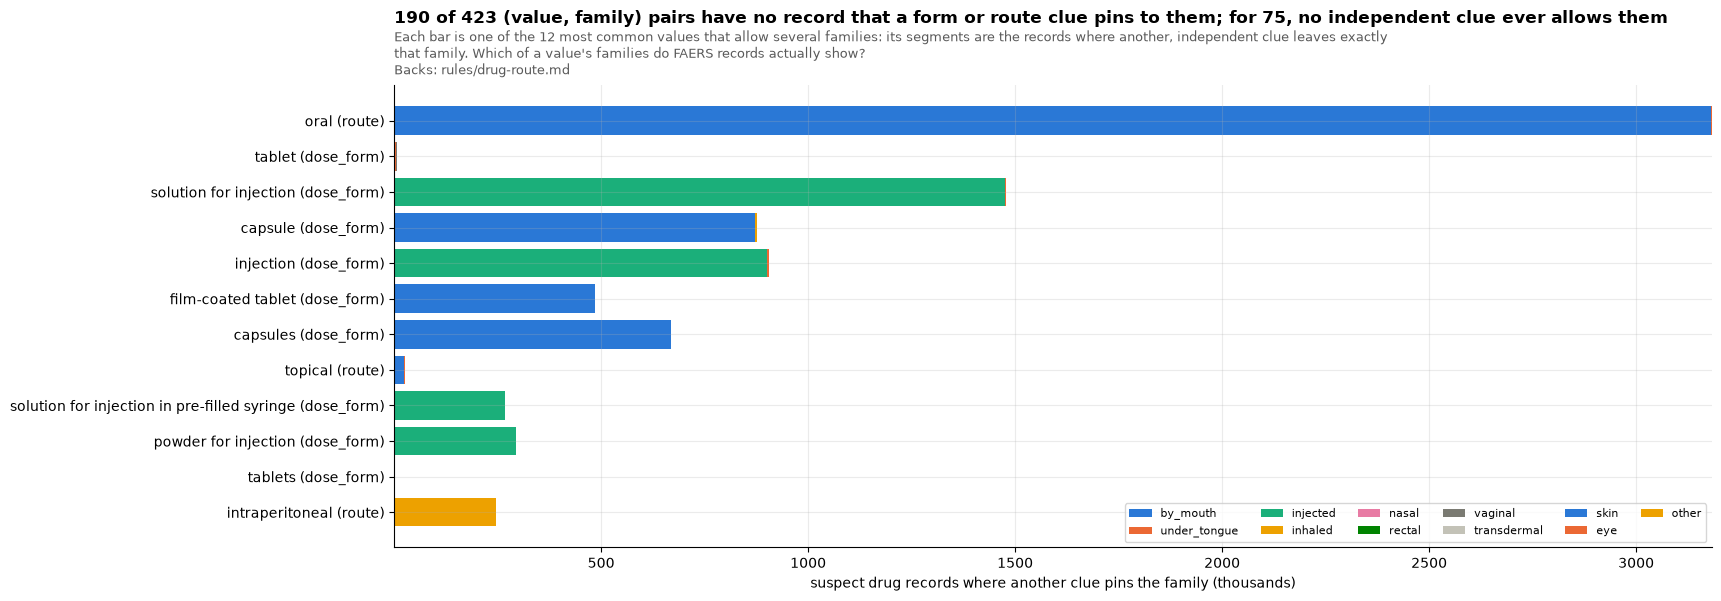

423 (value, family) pairs over 159 values that allow several families: 75 that no independent clue ever allows; 115 that a clue allows but never tells apart from another family; 65 with support under 1 in 1,000 of the value's records.


,source,value,family,records,allowed,support,support_cases,certain,breaks,top_ingredients
318,route,oral,by_mouth,10728381,6217185,3180824,2000754,7504257,3179935,"lenalidomide 602086, oxybate sodium 163514, oxycodone 13..."
201,route,oral,under_tongue,10728381,3038044,1612,1371,7504565,1612,"buprenorphine;naloxone 386, buprenorphine 299, asenapine..."
241,dose_form,tablet,under_tongue,4616461,2694856,4130,3183,2688898,4138,"buprenorphine;naloxone 936, fentanyl 902, buprenorphine 538"
235,dose_form,tablet,vaginal,4616461,3673,2696,1620,929,2598,"hydroxychloroquine 609, leflunomide 567, alendronic acid..."
351,dose_form,tablet,by_mouth,4616461,2689794,40,26,2687909,411,"alprazolam 3, amlodipine 3, amfetamine;dexamfetamine 2"
233,dose_form,solution for injection,injected,2446865,1484938,1476275,1057341,959100,1474873,"dupilumab 425678, adalimumab 86988, secukinumab 73988"
128,dose_form,solution for injection,eye,2446865,9304,618,507,960789,602,"talimogene laherparepvec 315, tocilizumab 120, glyceryl ..."
19,dose_form,capsule,by_mouth,1655927,871705,871705,628960,21,870879,"lenalidomide 91311, ibrutinib 48527, fingolimod 43166"
345,dose_form,capsule,inhaled,1655927,4257,4257,2685,7,4277,"treprostinil 1992, tiotropium 715, budesonide;formoterol..."
126,dose_form,capsule,vaginal,1655927,324,324,291,14,317,"progesterone 66, tacrolimus 24, atomoxetine 22"


In [8]:
pd.set_option("display.max_colwidth", 60)
# a value's independent clue: what the other fields on its row allow (for a route value, the
# dose form and name words; for a dose form or a name word, the route)
CLUE = {
    "route": ("rks", "CASE WHEN fi IS NULL THEN ni WHEN ni IS NULL THEN fi ELSE fi & ni END"),
    "dose_form": ("fks", "ri"),
    "drugname": ("nws", "ri"),
}
carry = " UNION ALL ".join(
    f"SELECT rid, multi, '{s}' AS source, unnest({col}) AS value, {clue} AS clue FROM w.unit_T"
    for s, (col, clue) in CLUE.items()
)
if not in_work("pair_T"):
    # one row per record, value that allows several families, and family of it: whether the
    # clue allows the family, and whether it pins the value to that family alone
    con.execute(f"""CREATE TABLE w.pair_T AS
        WITH p AS (
          SELECT v.rid, v.multi, v.source, v.value, b.family,
                 coalesce(v.clue & s.m & b.bit <> 0, false) AS allows,
                 coalesce(v.clue & s.m = b.bit, false) AS pins,
                 v.clue IS NOT NULL AS clued
          FROM ({carry}) v JOIN multi_df s USING (source, value)
          JOIN bits_df b ON s.m & b.bit <> 0)
        SELECT rid, source, value, family, allows, pins, clued FROM p WHERE NOT multi
        UNION ALL
        SELECT rid, source, value, family, bool_or(allows), bool_or(pins), bool_or(clued)
        FROM p WHERE multi
        GROUP BY ALL""")
counts = q("""SELECT source, value, family, count(*) AS records, count_if(allows) AS allowed,
                     count_if(pins) AS support, count_if(clued) AS with_clue
              FROM w.pair_T GROUP BY ALL""")
pinned = q("""
    WITH s AS (SELECT p.source, p.value, p.family, i.case_key_T, i.ing
               FROM w.pair_T p JOIN w.rid_T i USING (rid) WHERE p.pins),
    t AS (SELECT source, value, family, ing, count(*) AS n FROM s GROUP BY ALL),
    top AS (SELECT source, value, family,
                   string_agg(coalesce(ing, '?') || ' ' || n, ', ' ORDER BY n DESC, ing)
                     FILTER (WHERE r <= 3) AS top_ingredients
            FROM (SELECT *, row_number() OVER (PARTITION BY source, value, family
                                               ORDER BY n DESC, ing) AS r FROM t)
            GROUP BY ALL),
    c AS (SELECT source, value, family, count(DISTINCT case_key_T) AS support_cases
          FROM s GROUP BY ALL)
    SELECT * FROM c JOIN top USING (source, value, family)""")
evidence = (
    counts.merge(pinned, on=["source", "value", "family"], how="left")
    .fillna({"support_cases": 0, "top_ingredients": ""})
    .astype({"allowed": int, "support": int, "support_cases": int, "with_clue": int})
)
# what dropping each family alone would change, rebuilt exactly
moves = {
    (r.source, r.value, r.family): effect([(r.source, r.value, r.family)])
    for r in evidence.itertuples()
}
evidence["certain"] = [
    sum(n for (b, a), n in moves[k].items() if a == "one family")
    for k in zip(evidence.source, evidence.value, evidence.family, strict=True)
]
evidence["breaks"] = [
    sum(n for (b, a), n in moves[k].items() if b == "one family")
    for k in zip(evidence.source, evidence.value, evidence.family, strict=True)
]
evidence["share"] = evidence.support / evidence.records
evidence = evidence.sort_values(["records", "support", "family"], ascending=[False, False, True])
zero = evidence[(evidence.support == 0) & (evidence.allowed == 0)]
apart = evidence[(evidence.support == 0) & (evidence.allowed > 0)]
thin = evidence[(evidence.support > 0) & (evidence.share < 0.001)]
top_values = (
    evidence.groupby(["source", "value"]).records.first().sort_values(ascending=False).head(12)
)
fig, ax = plt.subplots(figsize=(17, 6))
labels_y = [f"{v} ({s})" for s, v in top_values.index]
left = np.zeros(len(top_values))
for i, f in enumerate(FAMS):
    vals = (
        np.array(
            [
                evidence[
                    (evidence.source == s) & (evidence.value == v) & (evidence.family == f)
                ].support.sum()
                for s, v in top_values.index
            ]
        )
        / 1e3
    )
    if vals.sum():
        ax.barh(labels_y[::-1], vals[::-1], left=left[::-1], color=SERIES[i % len(SERIES)], label=f)
        left += vals
ax.set_xlabel("suspect drug records where another clue pins the family (thousands)")
ax.legend(fontsize=8, ncol=6, loc="lower right")
title(
    ax,
    f"{len(zero) + len(apart)} of {len(evidence)} (value, family) pairs have no record that a "
    f"form or route clue pins to them; for {len(zero)}, no independent clue ever allows them",
    "Each bar is one of the 12 most common values that allow several families: its segments are the "
    "records where another, independent clue leaves exactly that family.",
    "Which of a value's families do FAERS records actually show?",
    width=150,
)
plt.show()
print(
    f"{len(evidence)} (value, family) pairs over {evidence.groupby(['source', 'value']).ngroups} values "
    f"that allow several families: {len(zero)} that no independent clue ever allows; {len(apart)} that a "
    f"clue allows but never tells apart from another family; {len(thin)} with support under 1 in 1,000 "
    "of the value's records."
)
evidence[
    [
        "source",
        "value",
        "family",
        "records",
        "allowed",
        "support",
        "support_cases",
        "certain",
        "breaks",
        "top_ingredients",
    ]
].head(60)

**Section 4, chart by chart**

- *The support table.* **Shows** every (value, family) pair of a value that allows several families: the suspect drug records carrying the value, those where an independent clue allows the family at all, those where it narrows the value to that family alone (in records and cases), what dropping the family alone would change (`certain`, `breaks`), and the three ingredients behind the support. **Point** 423 pairs over 159 values. Some families are plainly real: FDA's route `Oral` is narrowed to by mouth on 3.2 million records and under the tongue on 1,612 (buprenorphine with naloxone, asenapine). Others rest largely on reporters' mistakes: a plain `Tablet` narrowed to vaginal is led by hydroxychloroquine, leflunomide and alendronic acid (mostly FDA's route `Endocervical`, see the notes at the end), and a `Solution for injection` narrowed to the eye by talimogene laherparepvec and tocilizumab, though 9,304 records allow the eye, where intravitreal injections sit. **So what** The counts say which families FAERS shows; the ingredients say whether to believe them.
- *The largest values.* **Shows** the twelve most common values that allow several families, split by the family an independent clue pins. **Point** For most, nearly all the support falls in one family (by mouth for `Oral` and the plain capsule, injected for the injection forms); 75 pairs are never allowed by any independent clue, 115 are allowed but never told apart from another family (the skin against transdermal for a patch, by mouth against under the tongue under `Oral`), and 65 have support under 1 in 1,000 of the value's records. Dropping a family has a cost as well as a gain: taking vaginal from a plain `Tablet` would make 929 records certain but turn 2,598 records that are certain today into contradictions. **So what** These are the choices the closing Decisions section takes, each provisional until confirmed; only the five families FAERS shows solely as mistakes are out of the table.

## 5. Which ingredients' labels differ by form, and how many records they hold?

The label step's test build chose labels per ingredient (`label_candidates_T`). Here each label's families are the union of the sets of its route names in the same `families.csv`, so labels and reports are read in the same terms.

**The test.** For an ingredient with labels whose families differ: take every reaction reported with it on a suspect drug record in the default case set, counted in cases. A reaction is **named** by a label when its MedDRA term (as FAERS spells it) appears, as whole words, in the label's boxed warning, warnings and precautions, warnings, precautions or adverse reactions; letter case, punctuation and the British spellings `ae` and `oe` are ignored. A reaction **splits** when some of the ingredient's labels name it and others do not. An ingredient's labels **differ by form** when at least one in ten of its reported reactions that any of its labels names, counted in cases, splits. Plain whole-word matching misses many reactions a label states in other words. Where one label words a reaction as FAERS does and another in other words, the reaction counts as a split, so the test finds labels that name different reactions word for word: a difference in wording counts, as well as a difference in what the labels say.

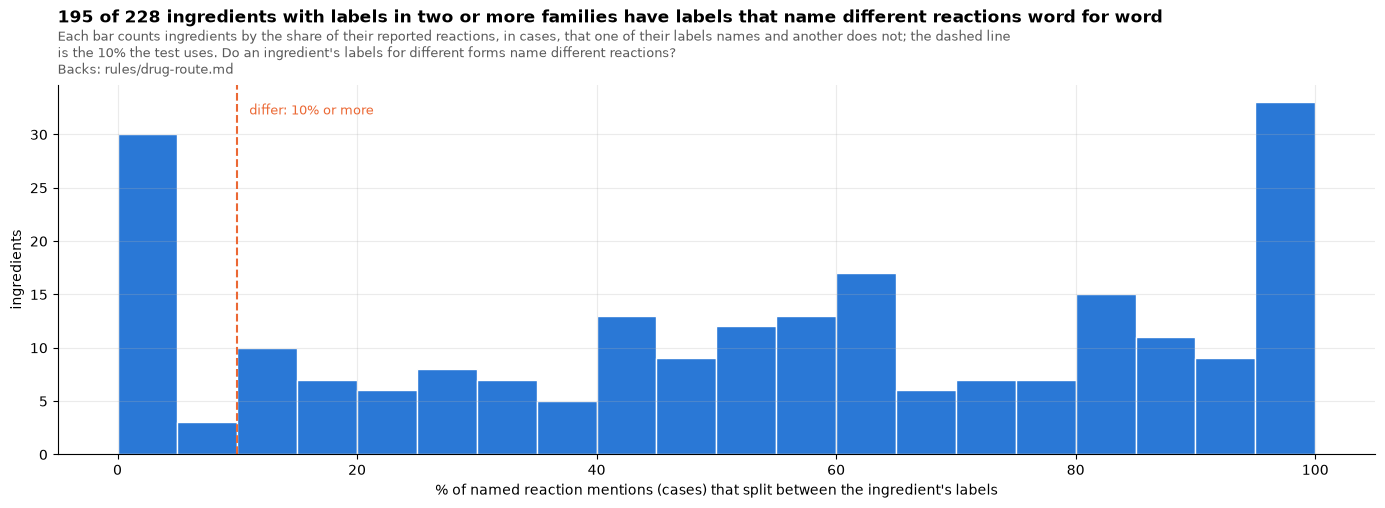

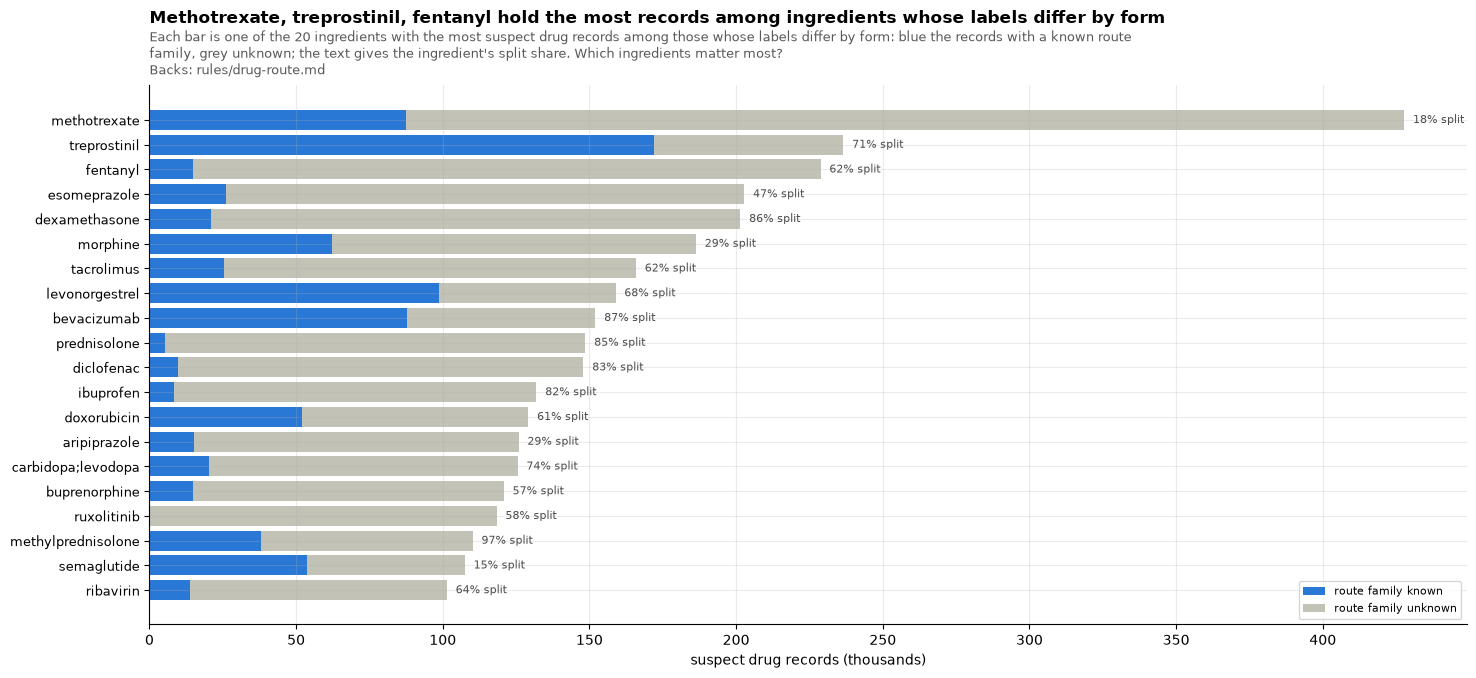

Ingredients with a label: 2,056; with labels in two or more families: 250; with safety text to compare on two or more: 228.
Their labels differ by form (10% or more split): 195 (at 5%: 198, at 20%: 178).
Those 195 ingredients hold 6,897,732 suspect drug records (16.8% of all) in 4,045,551 cases (19.9%).
Suspect drug records with an ingredient the labels hold: 35,504,262 of 41,002,690.
Labels: 2,401 (2,445 rows, a label listed under each of its ingredients); by how many families their routes allow: 1 904; 2 1259; 3 55; 4 1; 5 12; 9 157; 10 11; 11 2


In [9]:
lab = q(f"""SELECT array_to_string(list_sort(string_split(ingredient_T, ' / ')), ';') AS ing,
  ingredient_T, route_family_T AS step_family,
                   setid_T, title_T, routes_T
                     FROM read_parquet('{(LABELS / "label_candidates_T.parquet").as_posix()}')""")


# a label is in every family its route names allow
lab["fams"] = [";".join(sorted(T.label_families(list(routes)))) for routes in lab.routes_T]
lab = lab[lab.fams != ""]
con.register("lab_df", lab[["ing", "setid_T", "fams"]])
con.execute("CREATE OR REPLACE TEMP TABLE lab_T AS SELECT DISTINCT ing, setid_T, fams FROM lab_df")
con.execute("""CREATE OR REPLACE TEMP TABLE rec_ing_T AS
    WITH ings AS (SELECT DISTINCT ing FROM lab_T)
    SELECT r.*, coalesce(a.ing, b.ing) AS ing FROM w.rec_T r LEFT JOIN ings a ON a.ing = r.sub_T
      LEFT JOIN ings b ON b.ing = r.prod_ai_sub_T""")
multi = q("SELECT ing FROM lab_T GROUP BY ing HAVING count(DISTINCT fams) > 1").ing.tolist()
con.register("multi_df", pd.DataFrame({"ing": multi}))
ing_pt = q("""WITH c AS (SELECT DISTINCT era_T, primaryid, quarter_T, case_key_T, ing
  FROM rec_ing_T WHERE ing IN (SELECT ing FROM multi_df))
              SELECT c.ing, r.pt_norm_T AS pt, count(DISTINCT c.case_key_T) AS cases
              FROM c JOIN reac_latest_T r USING (era_T, primaryid, quarter_T)
                WHERE r.pt_norm_T IS NOT NULL GROUP BY ALL""")
SAFETY = (
    "boxed_warning",
    "warnings_and_precautions",
    "warnings",
    "precautions",
    "adverse_reactions",
)
texts = con.execute(f"""SELECT setid_T, string_agg(text_T, ' ' ORDER BY ordinal_T)
  FROM read_parquet('{(LABELS / "label_sections_T.parquet").as_posix()}')
                        WHERE section_T IN {SAFETY} AND setid_T IN (SELECT setid_T FROM lab_T
                          WHERE ing IN (SELECT ing FROM multi_df)) GROUP BY 1""").fetchall()


def words_of(s):
    return re.sub(r"(?<=[a-z])(ae|oe)(?=[a-z])", "e", re.sub(r"[^a-z0-9]+", " ", s.lower())).split()


phrases = {}
for setid, text in texts:
    w = words_of(text)
    phrases[setid] = {" ".join(w[i : i + n]) for n in range(1, 9) for i in range(len(w) - n + 1)}
labels_of = (
    q("SELECT * FROM lab_T")
    .groupby("ing")
    .apply(lambda g: [s for s in g.setid_T if s in phrases])
    .to_dict()
)
rows = []
for ing, pt, cases in ing_pt.itertuples(index=False):
    on = [" ".join(words_of(pt)) in phrases[s] for s in labels_of.get(ing, [])]
    if len(on) > 1:
        rows.append((ing, pt, cases, sum(on), len(on)))
pairs = pd.DataFrame(rows, columns=["ing", "pt", "cases", "n_on", "n_fam"])
named = pairs[pairs.n_on > 0].assign(split=lambda d: d.n_on < d.n_fam)
per = named.groupby("ing").apply(
    lambda g: pd.Series(
        {
            "named_cases": g.cases.sum(),
            "split_cases": g.cases[g.split].sum(),
            "named": len(g),
            "splits": int(g.split.sum()),
        }
    )
)
per["split_share"] = per.split_cases / per.named_cases
DIFFER = 0.10
differ = per[per.split_share >= DIFFER].index.tolist()
con.register("differ_df", pd.DataFrame({"ing": differ}))
held = q(f"""SELECT ing IN (SELECT ing FROM differ_df) AS differs,
  route_family_T <> '{UNKNOWN}' AS known, count(*) AS records,
                    count(DISTINCT case_key_T) AS cases FROM rec_ing_T WHERE ing IN (SELECT ing
                      FROM multi_df) GROUP BY ALL""")
held_cases = one(
    "SELECT count(DISTINCT case_key_T), count(*) FROM rec_ing_T WHERE ing IN (SELECT ing FROM "
    "differ_df)"
)
top = q(f"""SELECT ing, count(*) AS records, count(*)
  FILTER (WHERE route_family_T = '{UNKNOWN}') AS unknown FROM rec_ing_T
            WHERE ing IN (SELECT ing FROM differ_df) GROUP BY 1
              ORDER BY 2 DESC LIMIT 20""").set_index("ing")

fig, a1 = plt.subplots(figsize=(17, 4.8))
a1.hist(100 * per.split_share, bins=np.arange(0, 105, 5), color=SERIES[0], edgecolor="white")
a1.axvline(100 * DIFFER, color=SERIES[1], lw=1.5, ls="--")
a1.text(
    100 * DIFFER + 1,
    a1.get_ylim()[1] * 0.92,
    "differ: 10% or more",
    color=SERIES[1],
    fontsize=9,
)
a1.set_xlabel("% of named reaction mentions (cases) that split between the ingredient's labels")
a1.set_ylabel("ingredients")
title(
    a1,
    f"{len(differ)} of {len(per)} ingredients with labels in two or more families have labels "
    "that name different reactions word for word",
    "Each bar counts ingredients by the share of their reported reactions, in cases, that one of "
    "their labels names and another does not; "
    "the dashed line is the 10% the test uses.",
    "Do an ingredient's labels for different forms name different reactions?",
    width=150,
)
plt.show()
fig, a2 = plt.subplots(figsize=(17, 7))
y = np.arange(len(top))
a2.barh(y, (top.records - top.unknown) / 1e3, color=SERIES[0], label="route family known")
a2.barh(
    y,
    top.unknown / 1e3,
    left=(top.records - top.unknown) / 1e3,
    color=SERIES[7],
    label="route family unknown",
)
for i, ing in enumerate(top.index):
    a2.text(
        top.records[ing] / 1e3 + 3,
        i,
        f"{100 * per.split_share[ing]:.0f}% split",
        va="center",
        fontsize=8,
        color="0.3",
    )
a2.set_yticks(y)
a2.set_yticklabels(top.index, fontsize=9)
a2.invert_yaxis()
a2.set_xlabel("suspect drug records (thousands)")
a2.legend(fontsize=8, loc="lower right")
lead = ", ".join(top.index[:3])
title(
    a2,
    f"{lead[:1].upper() + lead[1:]} hold the most records among ingredients whose labels differ "
    "by form",
    "Each bar is one of the 20 ingredients with the most suspect drug records among those whose "
    "labels differ by form: blue the records "
    "with a known route family, grey unknown; the text gives the ingredient's split share.",
    "Which ingredients matter most?",
    width=150,
)
plt.show()
H = held.groupby("differs")[["records"]].sum().records
print(
    f"Ingredients with a label: {lab.ing.nunique():,}; with labels in two or more families: "
    f"{len(multi)}; with safety text to compare on two or more: {len(per)}."
)
print(
    f"Their labels differ by form (10% or more split): {len(differ)} (at 5%: "
    f"{(per.split_share >= 0.05).sum()}, at 20%: {(per.split_share >= 0.20).sum()})."
)
print(
    f"Those {len(differ)} ingredients hold {held_cases[1]:,} suspect drug records "
    f"({pct(held_cases[1], REC[0])} of all) in {held_cases[0]:,} cases "
    f"({pct(held_cases[0], REC[1])})."
)
print(
    "Suspect drug records with an ingredient the labels hold: "
    f"{one('SELECT count(ing) FROM rec_ing_T')[0]:,} of {REC[0]:,}."
)
labels_one = lab.drop_duplicates("setid_T")
print(
    f"Labels: {len(labels_one):,} ({len(lab):,} rows, a label listed under each of its "
    "ingredients); by how many families their routes allow: "
    + "; ".join(
        f"{n} {c}"
        for n, c in labels_one.fams.str.count(";").add(1).value_counts().sort_index().items()
    )
)

**Section 5, chart by chart**

- *Split share.* **Shows** ingredients by the share of their reported reactions, in cases, that one of their labels names and another does not. **Point** Of 2,056 ingredients with a label, 250 have labels whose families differ and 228 have safety text on two or more; for 195 the labels differ by form (198 at a 5% cut-off, 178 at 20%, so the cut-off hardly matters). Some sit near zero: one label text covers several forms. **So what** For 195 ingredients the matched label decides the flag of many reactions, so a record must be compared with the labels its families overlap, and the split shown where they disagree.
- *The largest ones.* **Shows** the 20 ingredients with the most suspect drug records among those whose labels differ, split by whether the record has exactly one family. **Point** The 195 hold 6,896,286 suspect drug records (16.8% of all) in 4,045,339 cases (19.9% of the default case set). **So what** Comparing several labels is not an edge case: it is the main path for some of the largest drugs.

The label set is the label step's test build, which chose one label per ingredient and family under earlier keys; where two of today's families were one then, the build often holds a label for only one of them. That makes the counts a floor. Whole-word matching moves them either way: it misses a reaction two labels both state in other words, and counts a reaction one label words as FAERS does and another does not as a split.

## 6. Which labels does each record match?

A record matches a label of its ingredient when the record's families and the label's families overlap. For a record whose families are not known, every label of the ingredient is a candidate. Where the matching labels agree on a reaction it is flagged as usual; where they disagree the split is shown ("on the tablet label, not on the gel label").

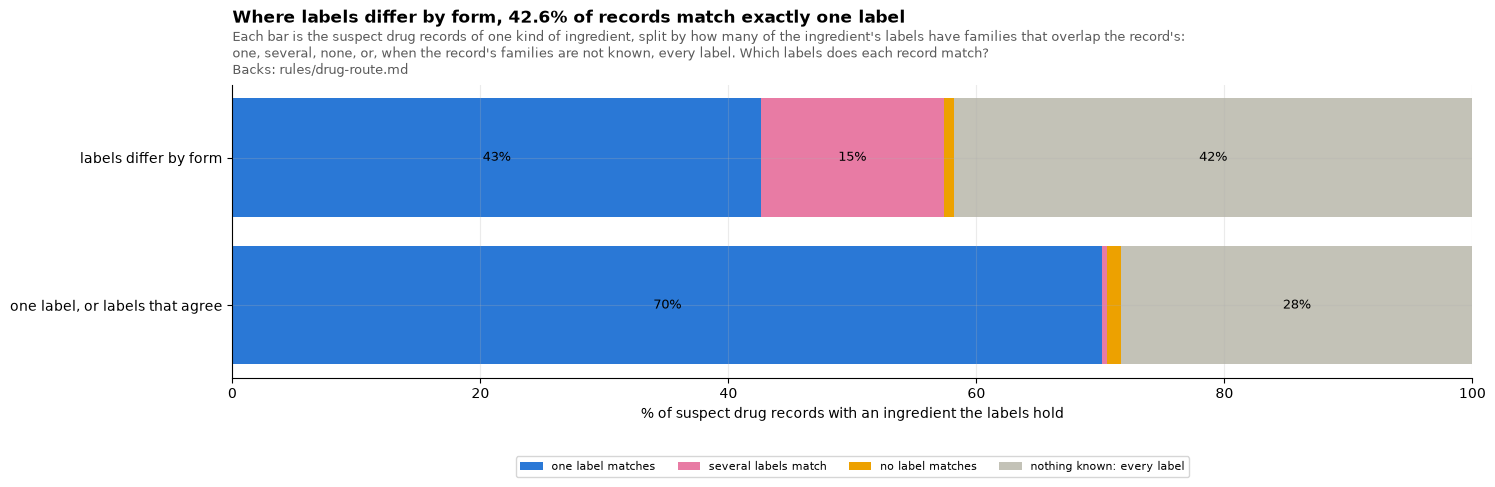

one label, or labels that agree: one label matches 20,065,383 (70.1%); several labels match 113,733 (0.4%); no label matches 325,405 (1.1%); nothing known: every label 8,102,009 (28.3%)
labels differ by form: one label matches 2,939,951 (42.6%); several labels match 1,016,120 (14.7%); no label matches 57,222 (0.8%); nothing known: every label 2,884,439 (41.8%)
Records that match no label of their ingredient: 382,627; the commonest: acetaminophen by_mouth;under_tongue (58,906), nicotine skin;transdermal (25,789), minoxidil rectal;skin;vaginal (22,720), minoxidil skin;transdermal (19,914), minoxidil skin (17,518), ethanol by_mouth;under_tongue (14,487), acetaminophen by_mouth;under_tongue;vaginal (10,849), iloprost inhaled (8,757), acetaminophen by_mouth (7,985), cortisone eye;nasal;rectal;skin;transdermal (7,908)


In [10]:
# each record's families against the families of its ingredient's labels: they match on overlap
groups = q("""SELECT ing, route_families_T AS fams, ing IN (SELECT ing FROM differ_df) AS differs,
                     count(*) AS records
              FROM rec_ing_T WHERE ing IS NOT NULL GROUP BY ALL""")
lab_sets = (
    q("SELECT ing, fams FROM lab_T")
    .groupby("ing")
    .fams.apply(lambda s: [set(x.split(";")) for x in s])
    .to_dict()
)


def matching(ing, fams):
    if not isinstance(fams, str):
        return "nothing known: every label"
    mine = set(fams.split(";"))
    n = sum(1 for x in lab_sets.get(ing, []) if x & mine)
    return "one label matches" if n == 1 else "several labels match" if n else "no label matches"


groups["what"] = [matching(i, f) for i, f in zip(groups.ing, groups.fams, strict=True)]
WHAT = [
    "one label matches",
    "several labels match",
    "no label matches",
    "nothing known: every label",
]
pv = (
    groups.pivot_table(index="differs", columns="what", values="records", aggfunc="sum")
    .reindex(columns=WHAT)
    .fillna(0)
)
nolabel = (
    groups[groups.what == "no label matches"]
    .groupby(["ing", "fams"])
    .records.sum()
    .sort_values(ascending=False)
    .head(10)
)
fig, ax = plt.subplots(figsize=(16, 3.8))
labels = {True: "labels differ by form", False: "one label, or labels that agree"}
left = np.zeros(len(pv))
for w, color in zip(WHAT, [SERIES[0], SERIES[4], SERIES[3], SERIES[7]], strict=True):
    vals = 100 * pv[w] / pv.sum(axis=1)
    ax.barh([labels[i] for i in pv.index], vals, left=left, color=color, label=w)
    for i, (v, start) in enumerate(zip(vals, left, strict=True)):
        if v >= 3:
            ax.text(start + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9)
    left += vals.values
ax.set_xlim(0, 100)
ax.set_xlabel("% of suspect drug records with an ingredient the labels hold")
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25))
d = pv.loc[True]
title(
    ax,
    f"Where labels differ by form, {pct(d['one label matches'], d.sum())} of records match "
    "exactly one label",
    "Each bar is the suspect drug records of one kind of ingredient, split by how many of the "
    "ingredient's labels have families that overlap the record's: one, several, none, or, when "
    "the record's families are not known, every label.",
    "Which labels does each record match?",
    width=150,
)
plt.show()
for d, row in pv.iterrows():
    print(
        f"{labels[d]}: "
        + "; ".join(f"{w} {int(row[w]):,} ({pct(row[w], row.sum())})" for w in WHAT)
    )
print(
    f"Records that match no label of their ingredient: {int(pv['no label matches'].sum()):,}; "
    "the commonest: " + ", ".join(f"{i} {f} ({n:,})" for (i, f), n in nolabel.items())
)

**Section 6, chart by chart**

- *Which labels match.* **Shows** suspect drug records with an ingredient the labels hold, split by how many of the ingredient's labels their families overlap. **Point** Where labels differ by form: 42.6% of records match exactly one label, 14.7% several, 0.8% none, and for 41.8% nothing is known, so every label is a candidate. Elsewhere: 70.1%, 0.4%, 1.1% and 28.3%. Across all ingredients 383,186 records match no label of their ingredient, mostly products sold over the counter whose only prescription label is another form: oral acetaminophen, nicotine patches, topical minoxidil. **So what** The label step needs three paths: one matching label, flagged against it; several, compared and the split shown; none, or nothing known, compared with every label of the ingredient.

## Decisions

Each choice the evidence leaves open, with the provisional decision taken (to be confirmed), what was picked, the alternatives and their numbers, and the commit on this branch that carries it, so that any one can be reverted alone (`git revert <commit>`, then run this notebook again). One principle runs through them: a value's families change only where FAERS shows a family is a mistake, never on absence of evidence. The numbers come from the release's own build, each record read again under the alternative; a record counts once. The (value, family) pairs behind decisions 3 and 4, and the thin ones, are listed after them.

In [11]:
# The commits on this branch that carry each decision, so any one can be reverted alone
# (git revert <commit>, then run this notebook again).
COMMITS = {
    "rows": "f3d1bfba",
    "removed": "caf9ef97",
    "kept": "97edc7f8",
}
removed = pd.read_csv(tables / "review" / "evidence-removals.csv", dtype=str, keep_default_na=False)


def made_certain(moves):
    return sum(n for (_, after), n in moves.items() if after == "one family")


def lines(moves):
    return "; ".join(
        f"{b} to {a} {n:,}" for (b, a), n in sorted(moves.items(), key=lambda x: -x[1])
    )


def as_names(m):
    return None if m is None else ";".join(sorted(f for f in FAMS if m & BIT[f]))


def masks_of(row):
    rk, fk, nw = row
    out = [mask(T.sets[("route", rk)])] if rk else []
    out += [mask(T.sets[("dose_form", fk)])] if fk else []
    return out + [mask(T.sets[("drugname", w)]) for w in (nw or "").split()]


def row_alone(row):
    ms = masks_of(row)
    if not ms:
        return None
    both = reduce(lambda a, b: a & b, ms)
    return both or reduce(lambda a, b: a | b, ms)


def rows_intersected(key):
    """The alternative: every source on every row of the record intersected together."""
    ms = [m for row in key for m in masks_of(row)]
    if not ms:
        return None, "none"
    both = reduce(lambda a, b: a & b, ms)
    return (both, "ok") if both else (reduce(lambda a, b: a | b, ms), DISAGREE)


# Decision 1: rows of one record
alt = Counter()
for key, fams, src, n in zip(P.key, P.fams, P.src, P.n, strict=True):
    m, s = rows_intersected(key)
    if as_names(m) != as_text(fams) or (s == DISAGREE) != (src == DISAGREE):
        before = shape(as_names(m), s)
        alone = before == "one family" and m in {row_alone(r) for r in key}
        alt[(before, shape(fams, src), alone)] += int(n)
rows_changed = sum(alt.values())
false_certain = sum(n for (b, a, alone), n in alt.items() if b == "one family" and not alone)
lost_certain = sum(n for (b, a, alone), n in alt.items() if b == "one family" and alone)
was_contradiction = sum(n for (b, a, _), n in alt.items() if b == "contradiction" and a != b)

# Decision 2: five families removed as mistakes
back = effect([], list(zip(removed.source, removed.value, removed.family, strict=True)))
wrong_certain = sum(n for (b, a), n in back.items() if a == "one family")
lose_mistake = sum(n for (b, a), n in back.items() if b == a == "several")

# Decision 3: no independent clue ever allows them
everything = effect(list(zip(zero.source, zero.value, zero.family, strict=True)))
emptied = [
    (s, v) for (s, v), g in zero.groupby(["source", "value"]) if set(g.family) == T.sets[(s, v)]
]
gone = sum(n for (_, after), n in everything.items() if after == "nothing known")
untestable = zero.groupby(["source", "value"]).with_clue.first()

# Decision 4: allowed but never told apart; how often the labels settle such records
lab_one = (
    groups[groups.what == "one label matches"].groupby("fams").records.sum()
    / groups.groupby("fams").records.sum()
).fillna(0)
two = [len(T.sets[(s, v)]) == 2 for s, v in zip(apart.source, apart.value, strict=True)]
largest_apart = (
    apart[two].sort_values("records", ascending=False).drop_duplicates(["source", "value"])
)

display(
    Markdown(
        f"""### 1. A record written on several rows

**Provisional decision (to be confirmed).** Each row is read alone, its sources intersected; the
record could be in every family one of its rows could be in. FDA writes one row per dosage
regimen, and two regimens of one drug can both be true.

*Alternative:* intersect every row of the record together (the reading before this decision).
It would change {rows_changed:,} suspect drug records: {false_certain:,} would be certain of a
family no row gives alone (rows `Oral` and `Topical` leave only `under_tongue`), and
{was_contradiction:,} whose rows give different families would be contradictions. On the other
side, {lost_certain:,} records that the alternative keeps certain (one row leaves one family,
another says less, such as the same dose form with no route) are not certain under this
decision.

*Commit:* `{COMMITS["rows"]}`.

### 2. Families FAERS shows only as mistakes

**Provisional decision (to be confirmed).** Remove the {len(removed)} families below; every
record that pins the value to them is a reporter's or coder's mistake. The other
{len(thin)} thin pairs stay: a real product given that way is among the drugs behind them.

"""
        + "\n".join(
            f"- `{r.value}` ({r.source}): `{r.family}`, {r.drugs or 'no record'}."
            for r in removed.itertuples()
        )
        + f"""

*Alternative:* keep them. {wrong_certain:,} records would be certain of the mistaken family
(today their sources contradict each other and their union holds the right one), and
{lose_mistake:,} would list it among several. Removing them makes no record certain.

*Commit:* `{COMMITS["removed"]}` (the table, with each removal and its reason in
`review/evidence-removals.csv`).

### 3. Families no independent clue ever allows ({len(zero)} pairs)

**Provisional decision (to be confirmed).** Keep all of them. Absence of evidence is not
evidence. They sit on {len(untestable)} values; {(untestable == 0).sum()} of them have no
record with any other clue, so FAERS could not show the family if it were real, and some are
real uses no clue can see (talc into the chest under `Intrathoracic`, an intestinal gel under `Intraduodenal`).

*Alternative:* drop them all. That would make {made_certain(everything):,} suspect drug records
certain (a record counts once), leave {len(emptied)} values saying nothing
({", ".join(f"`{v}`" for _, v in emptied)}) and {gone:,} records with nothing known.

*Commit:* `{COMMITS["kept"]}` (no table change; the table's README says why).

### 4. Families a clue allows but never tells apart ({len(apart)} pairs)

**Provisional decision (to be confirmed).** Keep all of them. FAERS cannot settle them, both
families are real products, and the label flags settle most such records by overlap: of
records with an ingredient the labels hold, {pct(lab_one.get("skin;transdermal", 0), 1)} of
those ending `skin;transdermal` and {pct(lab_one.get("eye;injected", 0), 1)} of those ending
`eye;injected` match exactly one label.

*Alternative:* drop one family of each value. For a value of two families, either side makes
the same records certain, so the choice would be a coin toss; the largest:

"""
        + "\n".join(
            f"- `{r.value}` ({r.source}), {r.records:,} records: dropping "
            + " or ".join(
                f"`{x.family}` makes {x.certain:,} certain"
                for x in apart[(apart.source == r.source) & (apart.value == r.value)].itertuples()
            )
            + "."
            for r in largest_apart.head(5).itertuples()
        )
        + f"""

*Commit:* `{COMMITS["kept"]}` (no table change; the table's README says why).
"""
    )
)
print(
    "Rows read together instead: "
    + "; ".join(
        f"{b} to {a}{' (a row alone gives it)' if alone else ''} {n:,}"
        for (b, a, alone), n in sorted(alt.items(), key=lambda x: -x[1])
    )
)
print("Keeping the removed families instead: " + lines(back))
print("Dropping every family no clue allows: " + lines(everything) + ".")

### 1. A record written on several rows

**Provisional decision (to be confirmed).** Each row is read alone, its sources intersected; the
record could be in every family one of its rows could be in. FDA writes one row per dosage
regimen, and two regimens of one drug can both be true.

*Alternative:* intersect every row of the record together (the reading before this decision).
It would change 11,998 suspect drug records: 3,367 would be certain of a
family no row gives alone (rows `Oral` and `Topical` leave only `under_tongue`), and
2,203 whose rows give different families would be contradictions. On the other
side, 4,312 records that the alternative keeps certain (one row leaves one family,
another says less, such as the same dose form with no route) are not certain under this
decision.

*Commit:* `f3d1bfba`.

### 2. Families FAERS shows only as mistakes

**Provisional decision (to be confirmed).** Remove the 5 families below; every
record that pins the value to them is a reporter's or coder's mistake. The other
65 thin pairs stay: a real product given that way is among the drugs behind them.

- `dry powder` (dose_form): `by_mouth`, tobramycin 11 (TOBI Podhaler), formoterol 1 (Foradil).
- `dry powder` (dose_form): `nasal`, tobramycin 1 (TOBI Podhaler).
- `pre-filled syringe` (dose_form): `under_tongue`, tocilizumab 6 (Actemra), omalizumab 1 (Xolair), somatropin 1 (Nutropin).
- `pre-filled` (drugname): `under_tongue`, adalimumab 1 (Humira).
- `prefilled` (drugname): `under_tongue`, no record.

*Alternative:* keep them. 21 records would be certain of the mistaken family
(today their sources contradict each other and their union holds the right one), and
22,703 would list it among several. Removing them makes no record certain.

*Commit:* `caf9ef97` (the table, with each removal and its reason in
`review/evidence-removals.csv`).

### 3. Families no independent clue ever allows (75 pairs)

**Provisional decision (to be confirmed).** Keep all of them. Absence of evidence is not
evidence. They sit on 40 values; 13 of them have no
record with any other clue, so FAERS could not show the family if it were real, and some are
real uses no clue can see (talc into the chest under `Intrathoracic`, an intestinal gel under `Intraduodenal`).

*Alternative:* drop them all. That would make 4,119 suspect drug records
certain (a record counts once), leave 15 values saying nothing
(`endosinusial use`, `epilesional use`, `extracorporeal use`, `intraductal`, `intraduodenal`, `intraoral`, `intrapleural use`, `occlusive dressing`, `orale`, `per oral`, `percutaneous jejunal tube`, `periodontal use`, `po`, `skin scarification`, `transmucosal`) and 99 records with nothing known.

*Commit:* `97edc7f8` (no table change; the table's README says why).

### 4. Families a clue allows but never tells apart (115 pairs)

**Provisional decision (to be confirmed).** Keep all of them. FAERS cannot settle them, both
families are real products, and the label flags settle most such records by overlap: of
records with an ingredient the labels hold, 68.4% of
those ending `skin;transdermal` and 92.2% of those ending
`eye;injected` match exactly one label.

*Alternative:* drop one family of each value. For a value of two families, either side makes
the same records certain, so the choice would be a coin toss; the largest:

- `cutaneous solution` (dose_form), 153,722 records: dropping `skin` makes 152,979 certain or `transdermal` makes 152,979 certain.
- `transdermal patch` (dose_form), 152,988 records: dropping `skin` makes 151,208 certain or `transdermal` makes 151,208 certain.
- `transdermal` (drugname), 37,544 records: dropping `skin` makes 36,883 certain or `transdermal` makes 36,883 certain.
- `patch` (drugname), 23,239 records: dropping `skin` makes 15,186 certain or `transdermal` makes 15,186 certain.
- `transdermal system` (dose_form), 17,723 records: dropping `skin` makes 17,643 certain or `transdermal` makes 17,643 certain.

*Commit:* `97edc7f8` (no table change; the table's README says why).


Rows read together instead: one family to several (a row alone gives it) 4,312; one family to several 3,367; contradiction to several 2,203; several to several 1,921; contradiction to contradiction 195
Keeping the removed families instead: several to several 22,703; contradiction to one family 21; contradiction to contradiction 3
Dropping every family no clue allows: several to several 19,528; several to one family 4,116; contradiction to contradiction 163; several to nothing known 99; contradiction to one family 3; contradiction to several 2.


**No independent clue ever allows it (75 pairs; decision 3: kept).**

- `dry powder` (dose_form): dropping `other` would make 0 suspect drug records certain; 18,939 carry the value.
- `dry powder` (dose_form): dropping `skin` would make 0 suspect drug records certain; 18,939 carry the value.
- `syringe` (drugname): dropping `other` would make 0 suspect drug records certain; 7,195 carry the value.
- `syringe` (drugname): dropping `rectal` would make 0 suspect drug records certain; 7,195 carry the value.
- `pre-filled` (drugname): dropping `eye` would make 83 suspect drug records certain; 6,765 carry the value.
- `pre-filled` (drugname): dropping `nasal` would make 0 suspect drug records certain; 6,765 carry the value.
- `pre-filled` (drugname): dropping `other` would make 0 suspect drug records certain; 6,765 carry the value.
- `pre-filled` (drugname): dropping `rectal` would make 0 suspect drug records certain; 6,765 carry the value.
- `prefilled` (drugname): dropping `nasal` would make 0 suspect drug records certain; 4,262 carry the value.
- `prefilled` (drugname): dropping `rectal` would make 0 suspect drug records certain; 4,262 carry the value.
- `caps` (drugname): dropping `vaginal` would make 11 suspect drug records certain; 1,255 carry the value.
- `endotracheal` (route): dropping `other` would make 0 suspect drug records certain; 543 carry the value.
- `intrathoracic` (route): dropping `other` would make 402 suspect drug records certain; 472 carry the value.
- `foam` (drugname): dropping `injected` would make 0 suspect drug records certain; 394 carry the value.
- `softgels` (drugname): dropping `vaginal` would make 157 suspect drug records certain; 291 carry the value.
- `endocervical use` (route): dropping `other` would make 39 suspect drug records certain; 281 carry the value.
- `by mouth` (route): dropping `under_tongue` would make 2 suspect drug records certain; 136 carry the value.
- `intratrachael` (route): dropping `other` would make 0 suspect drug records certain; 98 carry the value.
- `intraduodenal` (route): dropping `by_mouth` would make 72 suspect drug records certain; 72 carry the value.
- `intraduodenal` (route): dropping `other` would make 72 suspect drug records certain; 72 carry the value.
- `extra-amniotic` (route): dropping `other` would make 34 suspect drug records certain; 42 carry the value.
- `gastroenteral` (route): dropping `other` would make 0 suspect drug records certain; 23 carry the value.
- `gastroenteral` (route): dropping `rectal` would make 0 suspect drug records certain; 23 carry the value.
- `intra-cervical` (route): dropping `other` would make 0 suspect drug records certain; 21 carry the value.
- `intra-cervical` (route): dropping `vaginal` would make 0 suspect drug records certain; 21 carry the value.
- `respiratory` (route): dropping `nasal` would make 12 suspect drug records certain; 20 carry the value.
- `intracervical use` (route): dropping `other` would make 0 suspect drug records certain; 14 carry the value.
- `occlusive dressing` (route): dropping `skin` would make 10 suspect drug records certain; 13 carry the value.
- `occlusive dressing` (route): dropping `transdermal` would make 10 suspect drug records certain; 13 carry the value.
- `dental use` (route): dropping `other` would make 0 suspect drug records certain; 8 carry the value.
- `extraamniotic use` (route): dropping `other` would make 5 suspect drug records certain; 8 carry the value.
- `dental use` (route): dropping `under_tongue` would make 0 suspect drug records certain; 8 carry the value.
- `gastroenteral use` (route): dropping `other` would make 0 suspect drug records certain; 5 carry the value.
- `gastroenteral use` (route): dropping `rectal` would make 0 suspect drug records certain; 5 carry the value.
- `epilesional use` (route): dropping `other` would make 1 suspect drug records certain; 4 carry the value.
- `epilesional use` (route): dropping `skin` would make 1 suspect drug records certain; 4 carry the value.
- `po` (route): dropping `by_mouth` would make 3 suspect drug records certain; 3 carry the value.
- `intraoral` (route): dropping `by_mouth` would make 0 suspect drug records certain; 3 carry the value.
- `intraoral` (route): dropping `injected` would make 0 suspect drug records certain; 3 carry the value.
- `periodontal` (route): dropping `injected` would make 0 suspect drug records certain; 3 carry the value.
- `intraoral` (route): dropping `other` would make 0 suspect drug records certain; 3 carry the value.
- `periodontal` (route): dropping `other` would make 0 suspect drug records certain; 3 carry the value.
- `po` (route): dropping `under_tongue` would make 3 suspect drug records certain; 3 carry the value.
- `intraoral` (route): dropping `under_tongue` would make 0 suspect drug records certain; 3 carry the value.
- `opthalmic` (route): dropping `injected` would make 0 suspect drug records certain; 2 carry the value.
- `extracorporeal use` (route): dropping `injected` would make 2 suspect drug records certain; 2 carry the value.
- `intrapleural use` (route): dropping `injected` would make 1 suspect drug records certain; 2 carry the value.
- `extracorporeal use` (route): dropping `other` would make 2 suspect drug records certain; 2 carry the value.
- `intrapleural use` (route): dropping `other` would make 2 suspect drug records certain; 2 carry the value.
- `per oral` (route): dropping `by_mouth` would make 1 suspect drug records certain; 1 carry the value.
- `orale` (route): dropping `by_mouth` would make 1 suspect drug records certain; 1 carry the value.
- `percutaneous jejunal tube` (route): dropping `by_mouth` would make 1 suspect drug records certain; 1 carry the value.
- `topically` (route): dropping `ear` would make 0 suspect drug records certain; 1 carry the value.
- `topically` (route): dropping `eye` would make 0 suspect drug records certain; 1 carry the value.
- `intraductal` (route): dropping `injected` would make 0 suspect drug records certain; 1 carry the value.
- `periodontal use` (route): dropping `injected` would make 0 suspect drug records certain; 1 carry the value.
- `injested` (route): dropping `injected` would make 0 suspect drug records certain; 1 carry the value.
- `skin scarification` (route): dropping `injected` would make 1 suspect drug records certain; 1 carry the value.
- `endosinusial use` (route): dropping `injected` would make 1 suspect drug records certain; 1 carry the value.
- `endosinusial use` (route): dropping `nasal` would make 1 suspect drug records certain; 1 carry the value.
- `topically` (route): dropping `nasal` would make 0 suspect drug records certain; 1 carry the value.
- `transmucosal` (route): dropping `nasal` would make 1 suspect drug records certain; 1 carry the value.
- `periodontal use` (route): dropping `other` would make 0 suspect drug records certain; 1 carry the value.
- `intraductal` (route): dropping `other` would make 0 suspect drug records certain; 1 carry the value.
- `via j-tube` (route): dropping `other` would make 0 suspect drug records certain; 1 carry the value.
- `topically` (route): dropping `other` would make 0 suspect drug records certain; 1 carry the value.
- `percutaneous jejunal tube` (route): dropping `other` would make 1 suspect drug records certain; 1 carry the value.
- `topically` (route): dropping `rectal` would make 0 suspect drug records certain; 1 carry the value.
- `skin scarification` (route): dropping `skin` would make 1 suspect drug records certain; 1 carry the value.
- `per oral` (route): dropping `under_tongue` would make 1 suspect drug records certain; 1 carry the value.
- `periodontal use` (route): dropping `under_tongue` would make 0 suspect drug records certain; 1 carry the value.
- `transmucosal` (route): dropping `under_tongue` would make 1 suspect drug records certain; 1 carry the value.
- `topically` (route): dropping `under_tongue` would make 0 suspect drug records certain; 1 carry the value.
- `orale` (route): dropping `under_tongue` would make 1 suspect drug records certain; 1 carry the value.
- `topically` (route): dropping `vaginal` would make 0 suspect drug records certain; 1 carry the value.

**Allowed by a clue but never told apart from another family (115 pairs; decision 4: kept).**

- `topical` (route): dropping `ear` would make 0 suspect drug records certain; 648,414 carry the value.
- `cutaneous solution` (dose_form): dropping `skin` would make 152,979 suspect drug records certain and turn 109 records certain today into contradictions; 153,722 carry the value.
- `cutaneous solution` (dose_form): dropping `transdermal` would make 152,979 suspect drug records certain; 153,722 carry the value.
- `transdermal patch` (dose_form): dropping `skin` would make 151,208 suspect drug records certain; 152,988 carry the value.
- `transdermal patch` (dose_form): dropping `transdermal` would make 151,208 suspect drug records certain; 152,988 carry the value.
- `implant` (dose_form): dropping `eye` would make 489 suspect drug records certain; 67,994 carry the value.
- `implant` (dose_form): dropping `nasal` would make 149 suspect drug records certain; 67,994 carry the value.
- `cream` (dose_form): dropping `skin` would make 1,696 suspect drug records certain and turn 18 records certain today into contradictions; 49,901 carry the value.
- `cream` (dose_form): dropping `transdermal` would make 1,696 suspect drug records certain; 49,901 carry the value.
- `tab` (drugname): dropping `by_mouth` would make 23,295 suspect drug records certain and turn 2,851 records certain today into contradictions; 42,508 carry the value.
- `ointment` (dose_form): dropping `skin` would make 700 suspect drug records certain and turn 1 records certain today into contradictions; 39,442 carry the value.
- `ointment` (dose_form): dropping `transdermal` would make 700 suspect drug records certain; 39,442 carry the value.
- `transdermal` (drugname): dropping `skin` would make 36,883 suspect drug records certain; 37,544 carry the value.
- `transdermal` (drugname): dropping `transdermal` would make 36,883 suspect drug records certain and turn 32 records certain today into contradictions; 37,544 carry the value.
- `foam` (dose_form): dropping `skin` would make 0 suspect drug records certain; 26,683 carry the value.
- `foam` (dose_form): dropping `vaginal` would make 0 suspect drug records certain; 26,683 carry the value.
- `patch` (drugname): dropping `skin` would make 15,186 suspect drug records certain; 23,239 carry the value.
- `patch` (drugname): dropping `transdermal` would make 15,186 suspect drug records certain and turn 7,717 records certain today into contradictions; 23,239 carry the value.
- `transdermal system` (dose_form): dropping `skin` would make 17,643 suspect drug records certain; 17,723 carry the value.
- `transdermal system` (dose_form): dropping `transdermal` would make 17,643 suspect drug records certain; 17,723 carry the value.
- `cutaneous liquid` (dose_form): dropping `skin` would make 17,141 suspect drug records certain and turn 2 records certain today into contradictions; 17,276 carry the value.
- `cutaneous liquid` (dose_form): dropping `transdermal` would make 17,141 suspect drug records certain; 17,276 carry the value.
- `oral` (drugname): dropping `by_mouth` would make 5,465 suspect drug records certain and turn 7,572 records certain today into contradictions; 16,219 carry the value.
- `patch` (dose_form): dropping `skin` would make 13,244 suspect drug records certain; 13,353 carry the value.
- `patch` (dose_form): dropping `transdermal` would make 13,244 suspect drug records certain; 13,353 carry the value.
- `pre-filled syringe` (dose_form): dropping `eye` would make 14 suspect drug records certain; 13,183 carry the value.
- `pre-filled syringe` (dose_form): dropping `other` would make 0 suspect drug records certain; 13,183 carry the value.
- `pre-filled syringe` (dose_form): dropping `rectal` would make 0 suspect drug records certain; 13,183 carry the value.
- `odt` (drugname): dropping `by_mouth` would make 11,728 suspect drug records certain and turn 678 records certain today into contradictions; 12,838 carry the value.
- `vial` (dose_form): dropping `eye` would make 26 suspect drug records certain; 10,948 carry the value.
- `microspheres` (dose_form): dropping `other` would make 122 suspect drug records certain; 9,759 carry the value.
- `matrix patch` (dose_form): dropping `skin` would make 9,636 suspect drug records certain; 9,679 carry the value.
- `matrix patch` (dose_form): dropping `transdermal` would make 9,636 suspect drug records certain; 9,679 carry the value.
- `gastroenteral suspension` (dose_form): dropping `rectal` would make 5 suspect drug records certain; 8,588 carry the value.
- `cutaneous patch` (dose_form): dropping `skin` would make 7,942 suspect drug records certain; 7,973 carry the value.
- `cutaneous patch` (dose_form): dropping `transdermal` would make 7,942 suspect drug records certain; 7,973 carry the value.
- `lozenge` (dose_form): dropping `by_mouth` would make 4,470 suspect drug records certain; 7,309 carry the value.
- `syringe` (drugname): dropping `by_mouth` would make 4 suspect drug records certain and turn 2 records certain today into contradictions; 7,195 carry the value.
- `syringe` (drugname): dropping `eye` would make 151 suspect drug records certain; 7,195 carry the value.
- `syringe` (drugname): dropping `under_tongue` would make 3 suspect drug records certain; 7,195 carry the value.
- `aerosol` (dose_form): dropping `rectal` would make 0 suspect drug records certain; 7,153 carry the value.
- `aerosol` (dose_form): dropping `skin` would make 0 suspect drug records certain and turn 1 records certain today into contradictions; 7,153 carry the value.
- `aerosol` (dose_form): dropping `vaginal` would make 0 suspect drug records certain; 7,153 carry the value.
- `tabs` (drugname): dropping `by_mouth` would make 3,757 suspect drug records certain and turn 752 records certain today into contradictions; 6,629 carry the value.
- `medicated chewing-gum` (dose_form): dropping `by_mouth` would make 4,330 suspect drug records certain; 6,411 carry the value.
- `injectable` (drugname): dropping `eye` would make 2,221 suspect drug records certain; 6,100 carry the value.
- `irrigation` (route): dropping `other` would make 0 suspect drug records certain; 5,870 carry the value.
- `irrigation` (route): dropping `skin` would make 0 suspect drug records certain; 5,870 carry the value.
- `irrigation` (route): dropping `vaginal` would make 0 suspect drug records certain; 5,870 carry the value.
- `cream` (drugname): dropping `skin` would make 29 suspect drug records certain and turn 11 records certain today into contradictions; 5,777 carry the value.
- `cream` (drugname): dropping `transdermal` would make 29 suspect drug records certain; 5,777 carry the value.
- `vial` (drugname): dropping `eye` would make 1,471 suspect drug records certain; 4,323 carry the value.
- `prefilled` (drugname): dropping `eye` would make 8 suspect drug records certain; 4,262 carry the value.
- `prefilled` (drugname): dropping `other` would make 0 suspect drug records certain; 4,262 carry the value.
- `hemodialysis` (route): dropping `other` would make 911 suspect drug records certain; 3,246 carry the value.
- `topical` (drugname): dropping `skin` would make 201 suspect drug records certain and turn 20 records certain today into contradictions; 2,197 carry the value.
- `topical` (drugname): dropping `transdermal` would make 201 suspect drug records certain; 2,197 carry the value.
- `intravitreal use` (route): dropping `eye` would make 1,012 suspect drug records certain; 1,062 carry the value.
- `intratracheal` (route): dropping `other` would make 2 suspect drug records certain; 973 carry the value.
- `jejunal` (route): dropping `by_mouth` would make 946 suspect drug records certain; 948 carry the value.
- `jejunal` (route): dropping `other` would make 946 suspect drug records certain; 948 carry the value.
- `intravitreal` (route): dropping `eye` would make 866 suspect drug records certain; 921 carry the value.
- `intracavity` (route): dropping `other` would make 335 suspect drug records certain; 681 carry the value.
- `lozenge` (drugname): dropping `by_mouth` would make 473 suspect drug records certain; 633 carry the value.
- `percutaneous j-tube` (route): dropping `by_mouth` would make 533 suspect drug records certain; 533 carry the value.
- `percutaneous j-tube` (route): dropping `other` would make 533 suspect drug records certain; 533 carry the value.
- `occlusive dressing technique` (route): dropping `skin` would make 331 suspect drug records certain; 459 carry the value.
- `occlusive dressing technique` (route): dropping `transdermal` would make 331 suspect drug records certain; 459 carry the value.
- `foam` (drugname): dropping `vaginal` would make 0 suspect drug records certain; 394 carry the value.
- `cutaneous use` (route): dropping `transdermal` would make 103 suspect drug records certain; 298 carry the value.
- `retrobulbar` (route): dropping `eye` would make 242 suspect drug records certain; 247 carry the value.
- `transdermal use` (route): dropping `skin` would make 212 suspect drug records certain; 228 carry the value.
- `transdermal use` (route): dropping `transdermal` would make 212 suspect drug records certain; 228 carry the value.
- `patches` (drugname): dropping `skin` would make 159 suspect drug records certain; 162 carry the value.
- `patches` (drugname): dropping `transdermal` would make 159 suspect drug records certain; 162 carry the value.
- `suppositories` (drugname): dropping `other` would make 0 suspect drug records certain; 146 carry the value.
- `lozenges` (drugname): dropping `by_mouth` would make 123 suspect drug records certain and turn 1 records certain today into contradictions; 145 carry the value.
- `injection not otherwise specified` (route): dropping `eye` would make 112 suspect drug records certain; 114 carry the value.
- `injection not otherwise specified` (route): dropping `injected` would make 112 suspect drug records certain; 114 carry the value.
- `percutaneous j tube` (route): dropping `by_mouth` would make 112 suspect drug records certain; 113 carry the value.
- `percutaneous j tube` (route): dropping `other` would make 112 suspect drug records certain; 113 carry the value.
- `iontophoresis` (route): dropping `skin` would make 68 suspect drug records certain; 87 carry the value.
- `iontophoresis` (route): dropping `transdermal` would make 68 suspect drug records certain; 87 carry the value.
- `injection` (route): dropping `eye` would make 67 suspect drug records certain; 85 carry the value.
- `oropharyngeal` (route): dropping `under_tongue` would make 45 suspect drug records certain; 79 carry the value.
- `ocular use` (route): dropping `injected` would make 30 suspect drug records certain; 68 carry the value.
- `catheter` (route): dropping `by_mouth` would make 0 suspect drug records certain; 61 carry the value.
- `catheter` (route): dropping `injected` would make 0 suspect drug records certain; 61 carry the value.
- `catheter` (route): dropping `other` would make 0 suspect drug records certain; 61 carry the value.
- `subconjunctival use` (route): dropping `eye` would make 38 suspect drug records certain; 57 carry the value.
- `intraocular use` (route): dropping `injected` would make 24 suspect drug records certain; 33 carry the value.
- `intracameral use` (route): dropping `eye` would make 22 suspect drug records certain; 22 carry the value.
- `intracameral use` (route): dropping `injected` would make 22 suspect drug records certain; 22 carry the value.
- `oropharyngeal use` (route): dropping `under_tongue` would make 5 suspect drug records certain; 21 carry the value.
- `orally` (route): dropping `under_tongue` would make 8 suspect drug records certain; 9 carry the value.
- `percutaneous-j tube` (route): dropping `by_mouth` would make 8 suspect drug records certain; 8 carry the value.
- `percutaneous-j tube` (route): dropping `other` would make 8 suspect drug records certain; 8 carry the value.
- `implantation` (route): dropping `eye` would make 0 suspect drug records certain; 4 carry the value.
- `implantation` (route): dropping `injected` would make 0 suspect drug records certain; 4 carry the value.
- `implantation` (route): dropping `nasal` would make 0 suspect drug records certain; 4 carry the value.
- `jejunal tube` (route): dropping `by_mouth` would make 2 suspect drug records certain; 2 carry the value.
- `subretinal use` (route): dropping `eye` would make 2 suspect drug records certain; 2 carry the value.
- `subretinal use` (route): dropping `injected` would make 2 suspect drug records certain; 2 carry the value.
- `jejunal tube` (route): dropping `other` would make 2 suspect drug records certain; 2 carry the value.
- `percutaneous` (route): dropping `skin` would make 1 suspect drug records certain; 2 carry the value.
- `percutaneous` (route): dropping `transdermal` would make 1 suspect drug records certain; 2 carry the value.
- `tablet` (route): dropping `by_mouth` would make 0 suspect drug records certain; 1 carry the value.
- `injectable` (route): dropping `eye` would make 1 suspect drug records certain; 1 carry the value.
- `retrobulbar use` (route): dropping `eye` would make 1 suspect drug records certain; 1 carry the value.
- `injectable` (route): dropping `injected` would make 1 suspect drug records certain; 1 carry the value.
- `retrobulbar use` (route): dropping `injected` would make 1 suspect drug records certain; 1 carry the value.
- `topically` (route): dropping `skin` would make 1 suspect drug records certain; 1 carry the value.
- `topically` (route): dropping `transdermal` would make 1 suspect drug records certain; 1 carry the value.
- `tablet` (route): dropping `under_tongue` would make 0 suspect drug records certain; 1 carry the value.
- `tablet` (route): dropping `vaginal` would make 0 suspect drug records certain; 1 carry the value.

**Thin support, under 1 in 1,000 of the value's records (65 pairs; kept, with a real product among the drugs behind each).**

- `oral` (route): dropping `under_tongue` would make 7,504,565 suspect drug records certain and turn 1,612 records certain today into contradictions; 10,728,381 carry the value; support 1,612 records (buprenorphine;naloxone 386, buprenorphine 299, asenapine 148).
- `tablet` (dose_form): dropping `under_tongue` would make 2,688,898 suspect drug records certain and turn 4,138 records certain today into contradictions; 4,616,461 carry the value; support 4,130 records (buprenorphine;naloxone 936, fentanyl 902, buprenorphine 538).
- `tablet` (dose_form): dropping `vaginal` would make 929 suspect drug records certain and turn 2,598 records certain today into contradictions; 4,616,461 carry the value; support 2,696 records (hydroxychloroquine 609, leflunomide 567, alendronic acid 547).
- `tablet` (dose_form): dropping `by_mouth` would make 2,687,909 suspect drug records certain and turn 411 records certain today into contradictions; 4,616,461 carry the value; support 40 records (alprazolam 3, amlodipine 3, amfetamine;dexamfetamine 2).
- `solution for injection` (dose_form): dropping `eye` would make 960,789 suspect drug records certain and turn 602 records certain today into contradictions; 2,446,865 carry the value; support 618 records (talimogene laherparepvec 315, tocilizumab 120, glyceryl trinitrate 27).
- `capsule` (dose_form): dropping `vaginal` would make 14 suspect drug records certain and turn 317 records certain today into contradictions; 1,655,927 carry the value; support 324 records (progesterone 66, tacrolimus 24, atomoxetine 22).
- `film-coated tablet` (dose_form): dropping `vaginal` would make 372,452 suspect drug records certain and turn 204 records certain today into contradictions; 861,672 carry the value; support 210 records (leflunomide 78, anastrozole 52, cetirizine 11).
- `capsules` (dose_form): dropping `vaginal` would make 0 suspect drug records certain and turn 40 records certain today into contradictions; 679,522 carry the value; support 42 records (paracetamol 4, isotretinoin 3, lenalidomide 3).
- `capsules` (dose_form): dropping `inhaled` would make 0 suspect drug records certain and turn 25 records certain today into contradictions; 679,522 carry the value; support 25 records (mannitol 12, tiotropium 11, glycopyrronium 1).
- `topical` (route): dropping `other` would make 128 suspect drug records certain and turn 76 records certain today into contradictions; 648,414 carry the value; support 76 records (thrombin 56, calcium chloride;glucose;magnesium;sodium chloride;sodium lactate 9, thrombin human 6).
- `topical` (route): dropping `nasal` would make 1 suspect drug records certain and turn 65 records certain today into contradictions; 648,414 carry the value; support 65 records (salbutamol 14, mometasone 12, fluticasone 11).
- `topical` (route): dropping `under_tongue` would make 1,095 suspect drug records certain and turn 56 records certain today into contradictions; 648,414 carry the value; support 57 records (rimegepant 11, ? 10, miconazole 8).
- `topical` (route): dropping `transdermal` would make 172,660 suspect drug records certain and turn 24 records certain today into contradictions; 648,414 carry the value; support 24 records (rivastigmine 8, estradiol 6, nicotine 5).
- `topical` (route): dropping `rectal` would make 5 suspect drug records certain and turn 1 records certain today into contradictions; 648,414 carry the value; support 1 records (mesalazine 1).
- `solution for injection in pre-filled syringe` (dose_form): dropping `eye` would make 298,419 suspect drug records certain and turn 85 records certain today into contradictions; 565,583 carry the value; support 96 records (tocilizumab 86, certolizumab 3, adalimumab 2).
- `powder for injection` (dose_form): dropping `eye` would make 91,010 suspect drug records certain and turn 116 records certain today into contradictions; 385,835 carry the value; support 116 records (collagenase clostridium histolyticum 84, interferon alfa-2b 23, botulinum toxin 4).
- `tablets` (dose_form): dropping `under_tongue` would make 286,281 suspect drug records certain and turn 277 records certain today into contradictions; 308,680 carry the value; support 277 records (buprenorphine;naloxone 174, zolpidem 35, buprenorphine 30).
- `tablets` (dose_form): dropping `vaginal` would make 45 suspect drug records certain and turn 42 records certain today into contradictions; 308,680 carry the value; support 44 records (leflunomide 12, hydroxychloroquine 11, alendronic acid 9).
- `tablets` (dose_form): dropping `by_mouth` would make 286,236 suspect drug records certain and turn 16 records certain today into contradictions; 308,680 carry the value; support 1 records (levothyroxine 1).
- `capsule, hard` (dose_form): dropping `inhaled` would make 116,925 suspect drug records certain and turn 40 records certain today into contradictions; 255,128 carry the value; support 40 records (tiotropium 24, budesonide 4, fingolimod 3).
- `transdermal` (route): dropping `skin` would make 237,485 suspect drug records certain and turn 38 records certain today into contradictions; 248,981 carry the value; support 38 records (ketoconazole 26, ? 5, azelaic acid 3).
- `tablets` (drugname): dropping `vaginal` would make 56,874 suspect drug records certain and turn 164 records certain today into contradictions; 212,081 carry the value; support 161 records (misoprostol 146, ? 3, estradiol 2).
- `tablets` (drugname): dropping `by_mouth` would make 138,482 suspect drug records certain and turn 40,483 records certain today into contradictions; 212,081 carry the value; support 1 records (nifedipine 1).
- `ophthalmic` (route): dropping `injected` would make 68,588 suspect drug records certain and turn 140 records certain today into contradictions; 149,692 carry the value; support 140 records (bevacizumab 59, minoxidil 29, ceftazidime 7).
- `powder for solution for injection` (dose_form): dropping `eye` would make 58,076 suspect drug records certain and turn 25 records certain today into contradictions; 117,814 carry the value; support 26 records (botulinum toxin 11, bacitracin 5, methylprednisolone 3).
- `suspension for injection` (dose_form): dropping `eye` would make 52,779 suspect drug records certain and turn 42 records certain today into contradictions; 92,424 carry the value; support 42 records (triamcinolone 25, adalimumab 2, denosumab 2).
- `coated tablet` (dose_form): dropping `vaginal` would make 17,248 suspect drug records certain and turn 48 records certain today into contradictions; 90,156 carry the value; support 48 records (estradiol 25, misoprostol 13, fluvoxamine 2).
- `capsule` (drugname): dropping `vaginal` would make 28 suspect drug records certain and turn 7 records certain today into contradictions; 86,738 carry the value; support 9 records (progesterone 4, clotrimazole 2, econazole 2).
- `capsule` (drugname): dropping `inhaled` would make 54 suspect drug records certain and turn 5 records certain today into contradictions; 86,738 carry the value; support 4 records (tiotropium 3, ? 1).
- `lyophilized powder` (dose_form): dropping `by_mouth` would make 0 suspect drug records certain and turn 8 records certain today into contradictions; 84,006 carry the value; support 8 records (infliximab 7, ebastine 1).
- `injection` (drugname): dropping `eye` would make 25,127 suspect drug records certain and turn 31 records certain today into contradictions; 76,102 carry the value; support 57 records (sodium chloride 19, heparin 11, dexamethasone 8).
- `oral use` (route): dropping `under_tongue` would make 30,892 suspect drug records certain and turn 2 records certain today into contradictions; 47,784 carry the value; support 2 records (asenapine 1, melperone 1).
- `tablet` (drugname): dropping `vaginal` would make 1,388 suspect drug records certain and turn 14 records certain today into contradictions; 46,607 carry the value; support 10 records (misoprostol 5, estradiol 2, progesterone 2).
- `tablet` (drugname): dropping `by_mouth` would make 26,722 suspect drug records certain and turn 7,961 records certain today into contradictions; 46,607 carry the value; support 2 records (tetrabenazine 1, valganciclovir 1).
- `pen` (drugname): dropping `by_mouth` would make 22,981 suspect drug records certain and turn 14 records certain today into contradictions; 43,839 carry the value; support 17 records (phenoxymethylpenicillin 6, interferon beta-1a 3, benzylpenicillin 2).
- `tab` (drugname): dropping `vaginal` would make 224 suspect drug records certain and turn 3 records certain today into contradictions; 42,508 carry the value; support 2 records (estradiol 1, hydrochlorothiazide 1).
- `ointment` (dose_form): dropping `rectal` would make 0 suspect drug records certain and turn 34 records certain today into contradictions; 39,442 carry the value; support 34 records (lidocaine 17, glyceryl trinitrate 7, mupirocin 2).
- `injection, solution` (dose_form): dropping `eye` would make 5,937 suspect drug records certain and turn 1 records certain today into contradictions; 38,691 carry the value; support 1 records (tocilizumab 1).
- `orodispersible tablet` (dose_form): dropping `by_mouth` would make 29,934 suspect drug records certain and turn 1 records certain today into contradictions; 30,299 carry the value; support 1 records (vonoprazan 1).
- `intestinal gel` (dose_form): dropping `by_mouth` would make 29,031 suspect drug records certain and turn 3 records certain today into contradictions; 29,067 carry the value; support 3 records (benserazide;levodopa 1, carbidopa;levodopa 1, pramipexole 1).
- `intestinal gel` (dose_form): dropping `other` would make 29,031 suspect drug records certain and turn 1 records certain today into contradictions; 29,067 carry the value; support 1 records (carbidopa;levodopa 1).
- `capsules` (drugname): dropping `vaginal` would make 88 suspect drug records certain and turn 12 records certain today into contradictions; 26,737 carry the value; support 12 records (progesterone 7, ibuprofen 2, doxycycline 1).
- `foam` (dose_form): dropping `rectal` would make 0 suspect drug records certain and turn 10 records certain today into contradictions; 26,683 carry the value; support 10 records (budesonide 8, hydrocortisone;pramocaine 1, mesalazine 1).
- `dry powder` (dose_form): dropping `injected` would make 0 suspect drug records certain and turn 5 records certain today into contradictions; 18,939 carry the value; support 5 records (tobramycin 4, pamidronic acid 1).
- `inhaler` (dose_form): dropping `nasal` would make 12,937 suspect drug records certain and turn 16 records certain today into contradictions; 17,375 carry the value; support 17 records (fluticasone 6, budesonide;formoterol 2, salbutamol 2).
- `powder` (dose_form): dropping `other` would make 55 suspect drug records certain and turn 16 records certain today into contradictions; 16,720 carry the value; support 15 records (collagenase clostridium histolyticum 6, budesonide;formoterol 3, bcg vaccine 2).
- `powder` (dose_form): dropping `skin` would make 0 suspect drug records certain and turn 2 records certain today into contradictions; 16,720 carry the value; support 2 records (econazole 1, nystatin 1).
- `vial` (dose_form): dropping `inhaled` would make 0 suspect drug records certain and turn 9 records certain today into contradictions; 10,948 carry the value; support 9 records (dornase alfa 9).
- `vial` (dose_form): dropping `other` would make 0 suspect drug records certain and turn 1 records certain today into contradictions; 10,948 carry the value; support 1 records (bcg vaccine 1).
- `inj` (drugname): dropping `eye` would make 3,411 suspect drug records certain and turn 5 records certain today into contradictions; 9,108 carry the value; support 4 records (fluorouracil 3, bleomycin 1).
- `cap` (drugname): dropping `inhaled` would make 22 suspect drug records certain and turn 4 records certain today into contradictions; 9,022 carry the value; support 4 records (formoterol 2, multienzymes 1, tiotropium 1).
- `gastroenteral suspension` (dose_form): dropping `by_mouth` would make 17 suspect drug records certain and turn 5 records certain today into contradictions; 8,588 carry the value; support 5 records (carbidopa;levodopa 4, lansoprazole 1).
- `gastroenteral suspension` (dose_form): dropping `other` would make 22 suspect drug records certain and turn 1 records certain today into contradictions; 8,588 carry the value; support 1 records (carbidopa;levodopa 1).
- `endocervical` (route): dropping `other` would make 4,387 suspect drug records certain and turn 6 records certain today into contradictions; 8,335 carry the value; support 6 records (budesonide;formoterol 3, carbidopa;levodopa 1, infliximab 1).
- `suppository` (dose_form): dropping `other` would make 0 suspect drug records certain and turn 2 records certain today into contradictions; 7,905 carry the value; support 2 records (alprostadil 1, hydrocortisone;nitrofurantoin 1).
- `tabs` (drugname): dropping `vaginal` would make 40 suspect drug records certain and turn 5 records certain today into contradictions; 6,629 carry the value; support 5 records (estradiol 3, ? 2).
- `tablet, film coated` (dose_form): dropping `vaginal` would make 2,155 suspect drug records certain and turn 2 records certain today into contradictions; 6,483 carry the value; support 2 records (lamivudine 1, leflunomide 1).
- `irrigation` (route): dropping `nasal` would make 0 suspect drug records certain and turn 2 records certain today into contradictions; 5,870 carry the value; support 2 records (vitamin b12 2).
- `soln for inject in pre-filled syringe` (dose_form): dropping `eye` would make 895 suspect drug records certain and turn 1 records certain today into contradictions; 5,036 carry the value; support 1 records (tocilizumab 1).
- `vial` (drugname): dropping `other` would make 2 suspect drug records certain and turn 4 records certain today into contradictions; 4,323 carry the value; support 4 records (? 3, cyclophosphamide 1).
- `prefilled` (drugname): dropping `vaginal` would make 0 suspect drug records certain and turn 2 records certain today into contradictions; 4,262 carry the value; support 2 records (miconazole 1, tioconazole 1).
- `dental` (route): dropping `other` would make 51 suspect drug records certain and turn 1 records certain today into contradictions; 4,127 carry the value; support 1 records (carbidopa;levodopa 1).
- `topical` (drugname): dropping `other` would make 1 suspect drug records certain and turn 2 records certain today into contradictions; 2,197 carry the value; support 2 records (lidocaine 1, ? 1).
- `caps` (drugname): dropping `inhaled` would make 0 suspect drug records certain and turn 1 records certain today into contradictions; 1,255 carry the value; support 1 records (? 1).
- `intravitreal use` (route): dropping `injected` would make 1,010 suspect drug records certain and turn 1 records certain today into contradictions; 1,062 carry the value; support 1 records (bevacizumab 1).

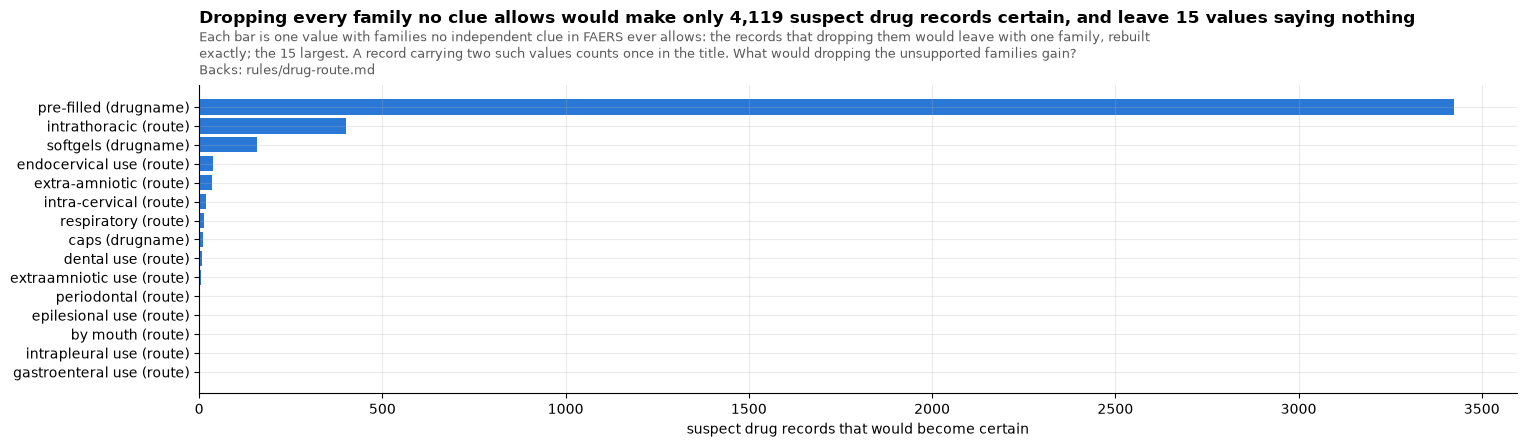

In [12]:
def choice_line(r):
    tail = f"; support {r.support:,} records ({r.top_ingredients})" if r.support else ""
    cost = f" and turn {r.breaks:,} records certain today into contradictions" if r.breaks else ""
    return (
        f"- `{r.value}` ({r.source}): dropping `{r.family}` would make {r.certain:,} suspect drug "
        f"records certain{cost}; {r.records:,} carry the value{tail}."
    )


display(
    Markdown(
        f"**No independent clue ever allows it ({len(zero)} pairs; decision 3: kept).**\n\n"
        + "\n".join(choice_line(r) for r in zero.itertuples())
        + f"\n\n**Allowed by a clue but never told apart from another family ({len(apart)} pairs; "
        "decision 4: kept).**\n\n"
        + "\n".join(choice_line(r) for r in apart.itertuples())
        + f"\n\n**Thin support, under 1 in 1,000 of the value's records ({len(thin)} pairs; kept, "
        "with a real product among the drugs behind each).**\n\n"
        + "\n".join(choice_line(r) for r in thin.itertuples())
    )
)
gain = (
    pd.Series(
        {
            (s, v): made_certain(effect(list(zip(g.source, g.value, g.family, strict=True))))
            for (s, v), g in zero.groupby(["source", "value"])
        }
    )
    .sort_values(ascending=False)
    .head(15)
)
fig, ax = plt.subplots(figsize=(17, 4))
ax.barh([f"{v} ({s})" for s, v in gain.index][::-1], gain.values[::-1], color=SERIES[0])
ax.set_xlabel("suspect drug records that would become certain")
title(
    ax,
    f"Dropping every family no clue allows would make only {made_certain(everything):,} suspect "
    f"drug records certain, and leave {len(emptied)} values saying nothing",
    "Each bar is one value with families no independent clue in FAERS ever allows: the records "
    "that dropping them would leave with one family, rebuilt exactly; the 15 largest. A record "
    "carrying two such values counts once in the title.",
    "What would dropping the unsupported families gain?",
    width=150,
)
plt.show()

## Two notes on FDA's route words

Neither changes the table; both are for whoever next reads FDA's route field.

In [13]:
def route_records(word):
    """Suspect drug records with a row whose FDA route is this word, by ingredient and year."""
    return q(f"""
        WITH r AS (SELECT DISTINCT rid FROM w.read_T WHERE rk = '{word}')
        SELECT i.ing, c.year_T, i.fams, count(*) AS records
        FROM r JOIN w.rid_T i USING (rid) JOIN w.rec_T c USING ({KEY}) GROUP BY ALL""")


def top(d, n=6):
    by = d.groupby("ing").records.sum().sort_values(ascending=False).head(n)
    return ", ".join(f"{i} {v:,}" for i, v in by.items())


endo = route_records("endocervical")
years = endo.groupby("year_T").records.sum()
thora = route_records("intrathoracic")
display(
    Markdown(
        f"""**FDA's route `Endocervical` is mostly a coding mistake.** {endo.records.sum():,}
suspect drug records have it, led by {top(endo)}: drugs swallowed or injected, not put into the
cervix. It has surged: {years[years.index < 2015].max():,} records in its largest year before
2015, {years.get(2023, 0):,} in 2023 and {years.get(2024, 0):,} in 2024. Today
{endo.records[endo.fams == "vaginal"].sum():,} of these records end certain as vaginal. Whether
`Endocervical` should say nothing, like `Unknown`, is open.

**`Intrathoracic` is often a mis-pick for `Intrathecal`.** Its {thora.records.sum():,} records
are led by {top(thora)}; most of the leaders are drugs often given into the spinal canal. Its real use, talc into the
chest for pleurodesis, is why the table keeps `other` for it."""
    )
)

**FDA's route `Endocervical` is mostly a coding mistake.** 8,335
suspect drug records have it, led by secukinumab 1,434, hydroxychloroquine 1,075, alendronic acid 757, leflunomide 728, certolizumab 726, cetirizine 276: drugs swallowed or injected, not put into the
cervix. It has surged: 13 records in its largest year before
2015, 993 in 2023 and 2,679 in 2024. Today
2,229 of these records end certain as vaginal. Whether
`Endocervical` should say nothing, like `Unknown`, is open.

**`Intrathoracic` is often a mis-pick for `Intrathecal`.** Its 472 records
are led by methotrexate 114, cytarabine 48, poractant alfa 33, morphine 27, iohexol 16, bupivacaine 16; most of the leaders are drugs often given into the spinal canal. Its real use, talc into the
chest for pleurodesis, is why the table keeps `other` for it.